Task 2:Stock Segmentation and Sensitivity Analysis

2.0 Environment Setup and Data Loading

In [74]:
!pip install scikit-learn seaborn matplotlib pandas numpy scipy -q

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from itertools import combinations

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.stats import skew

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plotting style & global colour palette
STYLE = 'seaborn-v0_8-whitegrid'
plt.style.use(STYLE if STYLE in plt.style.available else 'default')
plt.rcParams.update({'figure.autolayout': True, 'font.size': 11})
PALETTE = sns.color_palette('tab10', 10)

print("Libraries imported successfully.")

Libraries imported successfully.


In [76]:
# Load S&P 500 feature dataset indexed by Ticker
url = 'https://raw.githubusercontent.com/sathursiyakrishnamoorthy/sp500-RFM-Clustering/Files/features_task1_.csv'
df = pd.read_csv(url, index_col='Ticker')

print(f"Dataset shape: {df.shape[0]} shares x {df.shape[1]} columns")
print(f"Missing values per column:\n{df.isnull().sum().to_dict()}")
display(df.head())

Dataset shape: 482 shares x 7 columns
Missing values per column:
{'Mean_Weekly_Return': 0, 'Weekly_Beta': 0, 'Recency': 0, 'Frequency': 0, 'Monetary': 0, 'Security': 0, 'GICS Sector': 0}


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary,Security,GICS Sector
Ticker,,,,,,,
MMM,0.001142,0.869079,11,4,2.599146e+10,3M,Industrials
AOS,0.001991,1.042804,11,2,4.748980e+09,A. O. Smith,Industrials
ABT,0.000971,0.583543,11,1,3.523027e+10,Abbott Laboratories,Health Care
ABBV,0.003749,0.425366,11,3,6.837054e+10,AbbVie,Health Care
ACN,0.002376,1.143300,11,2,5.199430e+10,Accenture,Information Technology


2.1 Feature Preparation

In [77]:
# 2.1.1 Build the two raw feature matrices
rr_cols  = ['Mean_Weekly_Return', 'Weekly_Beta']
rfm_cols = ['Recency', 'Frequency', 'Monetary']

rr_raw  = df[rr_cols].copy()
rfm_raw = df[rfm_cols].copy()

print("Risk–Return raw shape:", rr_raw.shape)
print(rr_raw.describe().round(5))
print()
print("RFM raw shape:", rfm_raw.shape)
print(rfm_raw.describe().round(2))

Risk–Return raw shape: (482, 2)
       Mean_Weekly_Return  Weekly_Beta
count           482.00000    482.00000
mean              0.00284      0.96605
std               0.00264      0.38512
min              -0.00447      0.05545
25%               0.00118      0.66660
50%               0.00262      0.94606
75%               0.00421      1.17808
max               0.01777      2.50452

RFM raw shape: (482, 3)
       Recency  Frequency      Monetary
count   482.00     482.00  4.820000e+02
mean     20.37       2.98  3.958546e+10
std      21.39       1.33  1.296539e+11
min       4.00       0.00  1.297483e+09
25%      11.00       2.00  1.025102e+10
50%      11.00       3.00  1.668382e+10
75%      14.00       4.00  3.227689e+10
max     222.00       8.00  1.847697e+12


In [78]:
# 2.1.2 Skew and outlier inspection
all_cols = {
    'Mean_Weekly_Return': rr_raw['Mean_Weekly_Return'],
    'Weekly_Beta':        rr_raw['Weekly_Beta'],
    'Recency':            rfm_raw['Recency'],
    'Frequency':          rfm_raw['Frequency'],
    'Monetary':           rfm_raw['Monetary'],
}

skew_df = pd.DataFrame({
    'Skewness': {k: skew(v.dropna()) for k, v in all_cols.items()},
    'Min':      {k: v.min()          for k, v in all_cols.items()},
    'Max':      {k: v.max()          for k, v in all_cols.items()},
    'IQR':      {k: v.quantile(0.75) - v.quantile(0.25) for k, v in all_cols.items()},
}).round(4)

print("Feature skewness and range summary:")
display(skew_df)

# IQR-based outlier count per feature
print("\nIQR-based outlier counts (outside Q1 - 1.5*IQR  /  Q3 + 1.5*IQR):")
for name, s in all_cols.items():
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((s < Q1 - 1.5 * IQR) | (s > Q3 + 1.5 * IQR)).sum()
    print(f"  {name:<25s}: {n_out} outlier(s)")

Feature skewness and range summary:


,Skewness,Min,Max,IQR
Mean_Weekly_Return,0.8441,-4.500000e-03,1.780000e-02,3.000000e-03
Weekly_Beta,0.5282,5.550000e-02,2.504500e+00,5.115000e-01
Recency,3.6453,4.000000e+00,2.220000e+02,3.000000e+00
Frequency,0.4185,0.000000e+00,8.000000e+00,2.000000e+00
Monetary,11.6011,1.297483e+09,1.847697e+12,2.202587e+10



IQR-based outlier counts (outside Q1 - 1.5*IQR  /  Q3 + 1.5*IQR):
  Mean_Weekly_Return       : 14 outlier(s)
  Weekly_Beta              : 8 outlier(s)
  Recency                  : 117 outlier(s)
  Frequency                : 2 outlier(s)
  Monetary                 : 45 outlier(s)


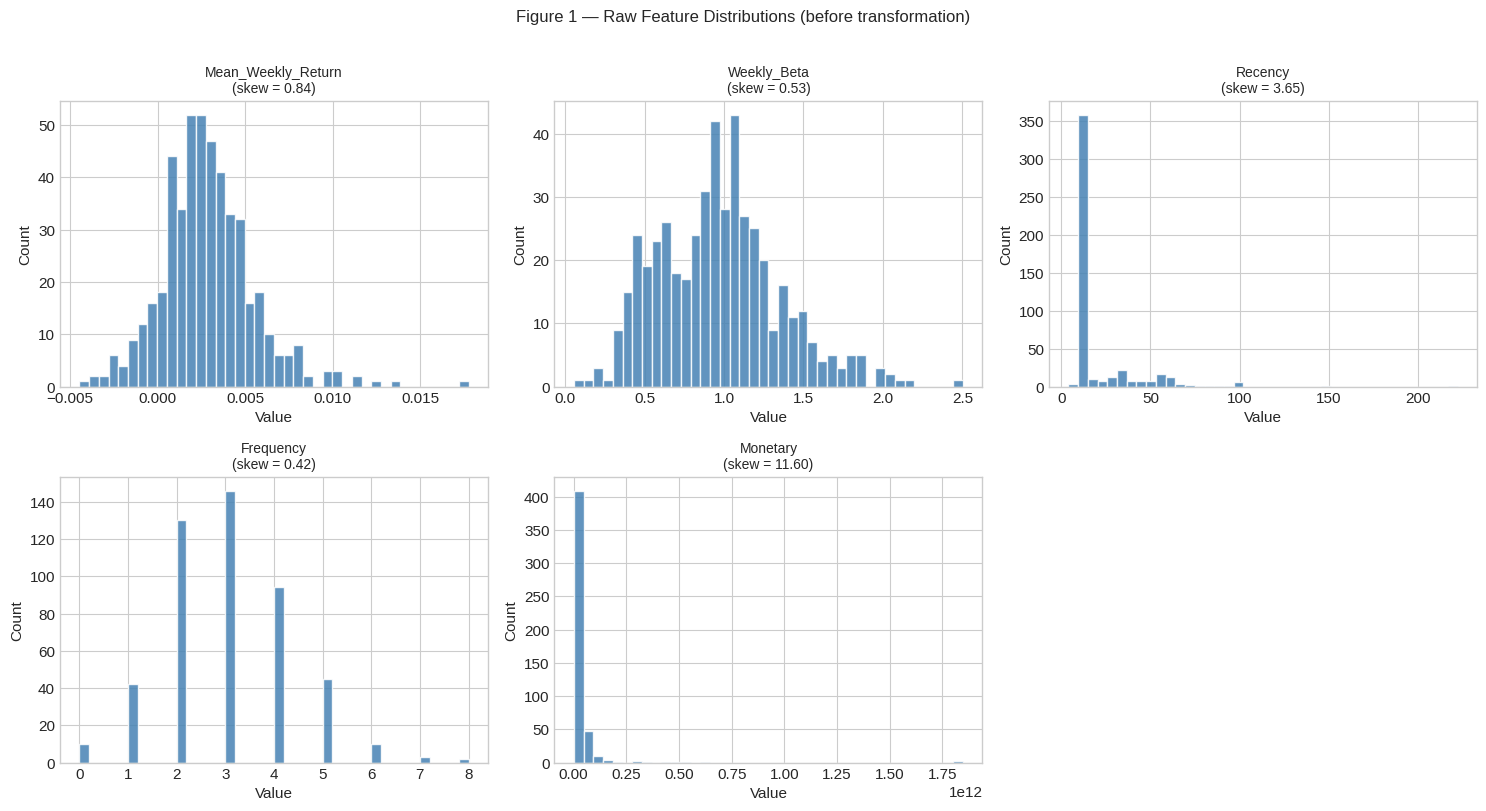

In [79]:
# 2.1.3 Distribution plots (before transformation)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (name, s) in zip(axes[:5], all_cols.items()):
    ax.hist(s.dropna(), bins=40, edgecolor='white', color='steelblue', alpha=0.85)
    ax.set_title(f'{name}\n(skew = {skew(s.dropna()):.2f})', fontsize=10)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

axes[5].axis('off')
fig.suptitle('Figure 1 — Raw Feature Distributions (before transformation)', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

In [80]:
# 2.1.4 Transformation and standardisation

# Apply log1p to Monetary: spans ~3 orders of magnitude, extreme right-skew.
rfm_tf = rfm_raw.copy()
rfm_tf['log1p_Monetary'] = np.log1p(rfm_tf['Monetary'])
rfm_tf = rfm_tf.drop(columns=['Monetary'])

# Risk–Return: no additional transformation (see Section 2.1.5 for rationale)
rr_tf = rr_raw.copy()

# Standardise each matrix independently — fit on its own features only
scaler_rr  = StandardScaler()
scaler_rfm = StandardScaler()

rr_scaled = pd.DataFrame(
    scaler_rr.fit_transform(rr_tf),
    index=rr_tf.index,
    columns=rr_tf.columns
)

rfm_scaled = pd.DataFrame(
    scaler_rfm.fit_transform(rfm_tf),
    index=rfm_tf.index,
    columns=rfm_tf.columns
)

# Keep clean copies for clustering — NEVER append cluster labels to these
rr_sc  = rr_scaled.copy()
rfm_sc = rfm_scaled.copy()

print("Risk–Return (standardised):")
print(rr_sc.agg(['mean', 'std']).round(6))
print()
print("RFM (standardised, log1p(M)):")
print(rfm_sc.agg(['mean', 'std']).round(6))

Risk–Return (standardised):
      Mean_Weekly_Return  Weekly_Beta
mean            0.000000     0.000000
std             1.001039     1.001039

RFM (standardised, log1p(M)):
       Recency  Frequency  log1p_Monetary
mean -0.000000  -0.000000        0.000000
std   1.001039   1.001039        1.001039


In [81]:
# 2.1.5 Skew treatment rationale — computed from actual data
computed_skew = {name: round(skew(s.dropna()), 4) for name, s in all_cols.items()}

print("Computed skewness values (from data):")
for k, v in computed_skew.items():
    print(f"  {k:<25s}: {v}")

print(f"""
Skew treatment rationale
========================
Feature               Skew (computed)   Action
--------------------  ---------------   -----------------------------------------------
Mean_Weekly_Return    {computed_skew['Mean_Weekly_Return']:<16.4f}  No transform. Moderate right-skew; range is
                                        bounded by the equity premium. Standardisation
                                        brings it to the same scale as Beta.

Weekly_Beta           {computed_skew['Weekly_Beta']:<16.4f}  No transform. Near-symmetric for large-cap
                                        S&P 500 constituents; outliers (Beta > 2) are
                                        genuine high-risk exposures, not data errors.

Recency               {computed_skew['Recency']:<16.4f}  No transform applied. Recency is bounded
                                        below (minimum ~4 days). Log would collapse the
                                        meaningful spread between recent (R=4) and stale
                                        (R=200+) events. Standardisation rescales without
                                        destroying interpretability of stale shares.

Frequency             {computed_skew['Frequency']:<16.4f}  No transform. Integer count 0–8; near-
                                        symmetric once standardised.

Monetary              {computed_skew['Monetary']:<16.4f}  log1p applied. Spans ~3 orders of magnitude
                                        (~$1.3bn to ~$1.8tn). Without compression,
                                        Euclidean distance is dominated entirely by M,
                                        reducing clustering to a size sort. log1p is
                                        preferred over log because log1p(0) = 0.
""")

Computed skewness values (from data):
  Mean_Weekly_Return       : 0.8441
  Weekly_Beta              : 0.5282
  Recency                  : 3.6453
  Frequency                : 0.4185
  Monetary                 : 11.6011

Skew treatment rationale
Feature               Skew (computed)   Action
--------------------  ---------------   -----------------------------------------------
Mean_Weekly_Return    0.8441            No transform. Moderate right-skew; range is
                                        bounded by the equity premium. Standardisation
                                        brings it to the same scale as Beta.

Weekly_Beta           0.5282            No transform. Near-symmetric for large-cap
                                        S&P 500 constituents; outliers (Beta > 2) are
                                        genuine high-risk exposures, not data errors.

Recency               3.6453            No transform applied. Recency is bounded
                                  

In [82]:
# 2.1.6 Four baseline solutions (k=4 as reference before tuning)
K_BASELINE = 4

agg_rr_base_labels  = AgglomerativeClustering(n_clusters=K_BASELINE, linkage='ward').fit_predict(rr_sc)
agg_rfm_base_labels = AgglomerativeClustering(n_clusters=K_BASELINE, linkage='ward').fit_predict(rfm_sc)
km_rr_base_labels   = KMeans(n_clusters=K_BASELINE, n_init=20, random_state=RANDOM_STATE).fit_predict(rr_sc)
km_rfm_base_labels  = KMeans(n_clusters=K_BASELINE, n_init=20, random_state=RANDOM_STATE).fit_predict(rfm_sc)

for label, lbls, X in [
    ('Agg RR  (Ward, k=4)',  agg_rr_base_labels,  rr_sc),
    ('Agg RFM (Ward, k=4)',  agg_rfm_base_labels, rfm_sc),
    ('KMeans RR  (k=4)',     km_rr_base_labels,   rr_sc),
    ('KMeans RFM (k=4)',     km_rfm_base_labels,  rfm_sc),
]:
    sil   = silhouette_score(X, lbls)
    sizes = pd.Series(lbls).value_counts().sort_index().tolist()
    print(f"{label:<28s} | silhouette={sil:.3f} | sizes={sizes}")

Agg RR  (Ward, k=4)          | silhouette=0.270 | sizes=[196, 122, 35, 129]
Agg RFM (Ward, k=4)          | silhouette=0.287 | sizes=[81, 205, 154, 42]
KMeans RR  (k=4)             | silhouette=0.320 | sizes=[51, 125, 160, 146]
KMeans RFM (k=4)             | silhouette=0.342 | sizes=[210, 61, 121, 90]


RR {2: np.float64(1.94), 3: np.float64(5.3), 4: np.float64(0.79), 5: np.float64(3.84), 6: np.float64(2.76), 7: np.float64(0.24)}
RFM {2: np.float64(3.81), 3: np.float64(7.3), 4: np.float64(0.51), 5: np.float64(1.49), 6: np.float64(2.26), 7: np.float64(0.78)}


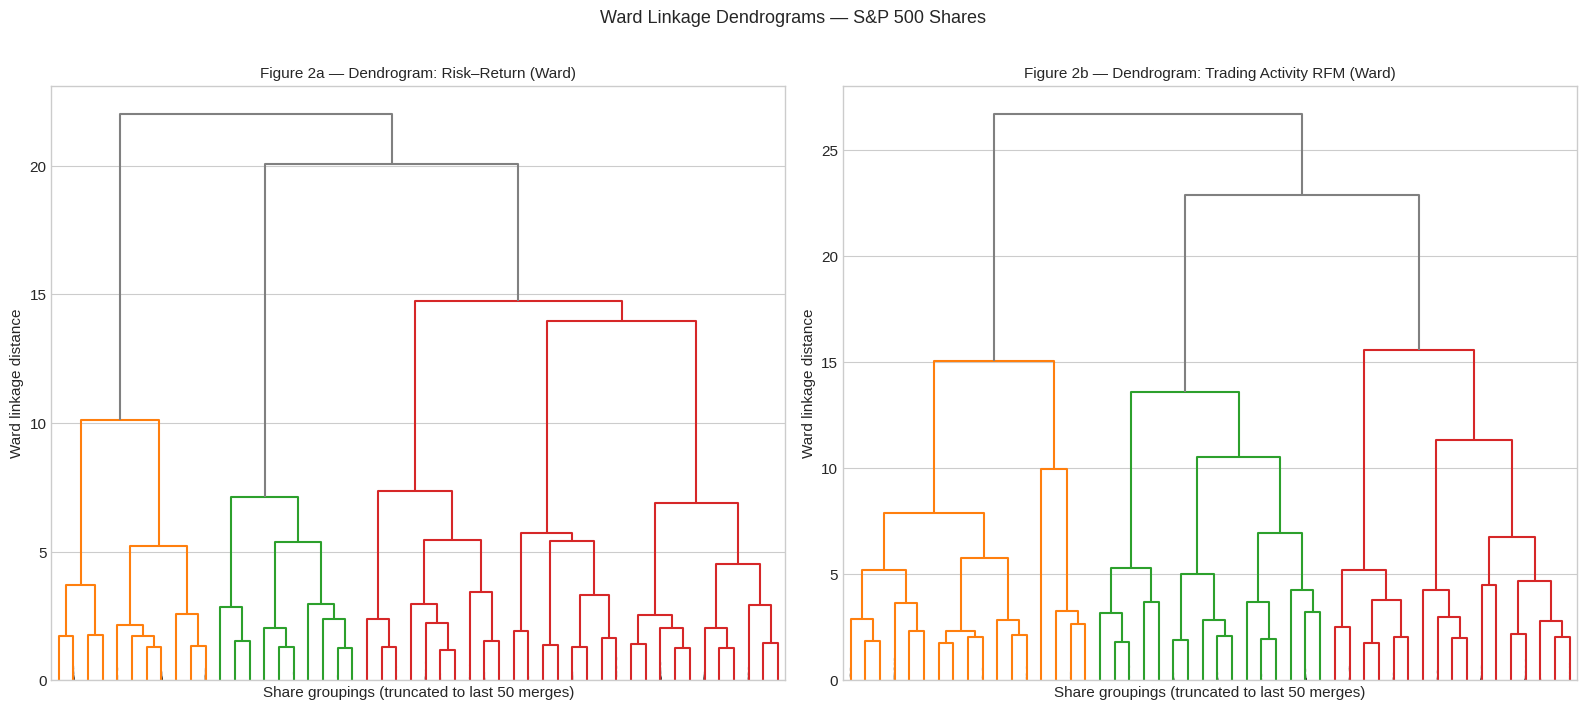

In [83]:
# 2.2.1 Ward linkage matrices and truncated dendrograms
Z_rr  = linkage(rr_sc,  method='ward', metric='euclidean')
Z_rfm = linkage(rfm_sc, method='ward', metric='euclidean')

# Linkage height gaps between consecutive merges (supports dendrogram cut discussion)
for n, Z in [('RR', Z_rr), ('RFM', Z_rfm)]:
    h = Z[:, 2][::-1]
    print(n, {k: round(h[k-2] - h[k-1], 2) for k in range(2, 8)})

def plot_dendrogram(Z, title, ax, p=50):
    dendrogram(
        Z, ax=ax,
        truncate_mode='lastp', p=p,
        show_contracted=True,
        above_threshold_color='grey',
        no_labels=True
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Share groupings (truncated to last 50 merges)')
    ax.set_ylabel('Ward linkage distance')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_dendrogram(Z_rr,  'Figure 2a — Dendrogram: Risk–Return (Ward)',         axes[0])
plot_dendrogram(Z_rfm, 'Figure 2b — Dendrogram: Trading Activity RFM (Ward)', axes[1])
fig.suptitle('Ward Linkage Dendrograms — S&P 500 Shares', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [84]:
# 2.2.2 Cluster selection constants and helper function
n_shares          = len(rr_sc)   # number of shares entering clustering
MIN_K             = 3            # k=2 gives one meaningful group and one "everything else" bin
MIN_CLUSTER_SHARE = 0.05         # clusters smaller than 5% of shares are not interpretable segments

print(f"Selection rule : k >= {MIN_K},  min cluster share >= {MIN_CLUSTER_SHARE:.0%} of shares")
print(f"Min cluster size in absolute terms: >= {np.ceil(MIN_CLUSTER_SHARE * n_shares):.0f} shares (n = {n_shares})")

def select_best_k(scan_df, model_name):
    """Select k >= MIN_K with min cluster share >= MIN_CLUSTER_SHARE maximizing silhouette."""
    feasible = scan_df[scan_df['feasible']]
    if feasible.empty:
        print(f"[Warning] No k met the >= {MIN_CLUSTER_SHARE:.0%} size rule for {model_name}; falling back to k >= {MIN_K}.")
        feasible = scan_df[scan_df['k'] >= MIN_K]
    best_row = feasible.loc[feasible['silhouette'].idxmax()]
    return int(best_row['k']), float(best_row['silhouette'])

Selection rule : k >= 3,  min cluster share >= 5% of shares
Min cluster size in absolute terms: >= 25 shares (n = 482)


In [85]:
# 2.2.2b Linkage comparison to choose the most suitable
# Same standardised features, same selection rule (k>=3, smallest cluster >=5%).
from scipy.cluster.hierarchy import linkage, fcluster, cophenet
from scipy.spatial.distance import pdist

methods = ['ward', 'average', 'complete', 'single']
rows = []
for space, X in [('Risk-return', rr_sc), ('RFM', rfm_sc)]:
    d = pdist(X.values)
    for m in methods:
        Z = linkage(X.values, method=m, metric='euclidean')
        coph, _ = cophenet(Z, d)
        sizes6 = sorted(np.bincount(fcluster(Z, 6, criterion='maxclust'))[1:], reverse=True)
        best = None
        for k in range(MIN_K, 9):
            lab = fcluster(Z, k, criterion='maxclust')
            sizes = np.bincount(lab)[1:]
            if len(sizes) == k and sizes.min() >= MIN_CLUSTER_SHARE * n_shares:
                s = silhouette_score(X.values, lab)
                if best is None or s > best[1]:
                    best = (k, s)
        rows.append({'Feature set': space, 'Linkage': m,
                     'Cophenetic corr.': round(coph, 3),
                     'Allowed k found': best[0] if best else 'none',
                     'Best silhouette': round(best[1], 3) if best else None,
                     'Cluster sizes at k=6': [int(x) for x in sizes6]})
display(pd.DataFrame(rows))

,Feature set,Linkage,Cophenetic corr.,Allowed k found,Best silhouette,Cluster sizes at k=6
0,Risk-return,ward,0.514,6,0.320,"[149, 129, 66, 56, 47, 35]"
1,Risk-return,average,0.771,none,NaN,"[435, 29, 13, 3, 1, 1]"
2,Risk-return,complete,0.554,none,NaN,"[254, 146, 52, 19, 7, 4]"
3,Risk-return,single,0.729,none,NaN,"[476, 2, 1, 1, 1, 1]"
4,RFM,ward,0.509,3,0.305,"[205, 136, 71, 42, 18, 10]"
5,RFM,average,0.840,none,NaN,"[443, 16, 11, 10, 1, 1]"
6,RFM,complete,0.595,none,NaN,"[293, 134, 30, 15, 9, 1]"
7,RFM,single,0.668,none,NaN,"[477, 1, 1, 1, 1, 1]"


Agglomerative — Risk–Return (Feasible = k>=3 AND min cluster >=5%):
 k  silhouette  min_size                             sizes  feasible
 2    0.267751       122                        [360, 122]     False
 3    0.302359        35                    [325, 122, 35]      True
 4    0.269798        35               [196, 129, 122, 35]      True
 5    0.314376        35           [149, 129, 122, 47, 35]      True
 6    0.319940        35        [149, 129, 66, 56, 47, 35]      True
 7    0.316874        16    [149, 113, 66, 56, 47, 35, 16]     False
 8    0.319050         4 [149, 113, 66, 56, 47, 31, 16, 4]     False

Agglomerative — RFM:
 k  silhouette  min_size                             sizes  feasible
 2    0.370750        81                         [401, 81]     False
 3    0.304883        81                    [247, 154, 81]      True
 4    0.286756        42                [205, 154, 81, 42]      True
 5    0.302785        10            [205, 154, 71, 42, 10]     False
 6    0.31300

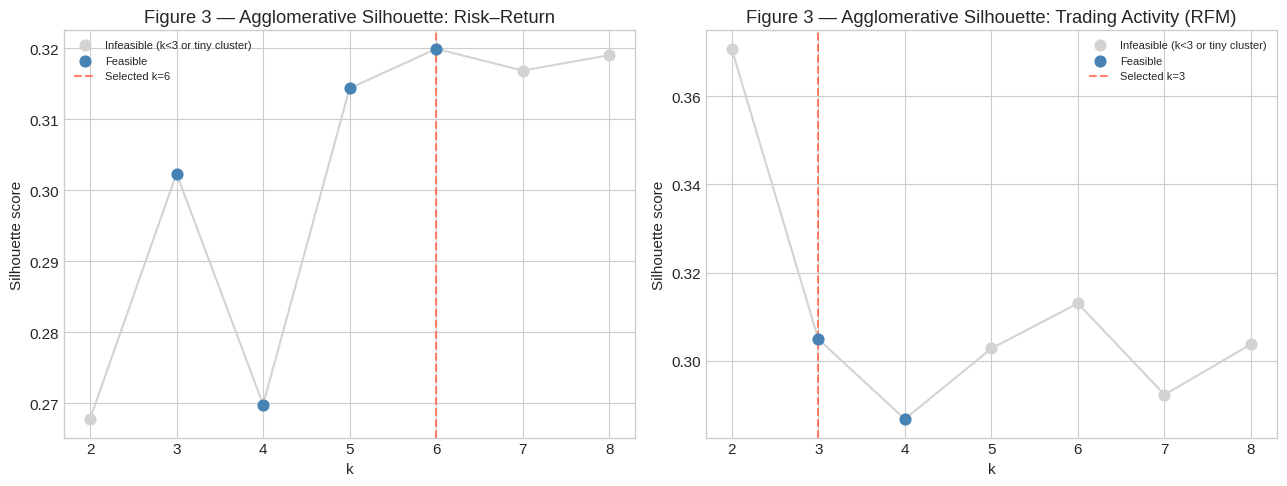

In [86]:
# 2.2.3 Silhouette scan k=2 to 8 — Agglomerative (Ward)
# Selection rule:
#   1. Discard any k < MIN_K (too coarse to profile)
#   2. Discard any k where the smallest cluster < MIN_CLUSTER_SHARE of shares
#   3. Among remaining feasible k, select the highest silhouette score

K_RANGE = range(2, 9)
agg_rr_results  = []
agg_rfm_results = []

for k in K_RANGE:
    # Risk–Return
    lbls_rr     = fcluster(Z_rr, t=k, criterion='maxclust') - 1
    sizes_rr    = pd.Series(lbls_rr).value_counts().sort_values(ascending=False).tolist()
    feasible_rr = (k >= MIN_K) and (len(sizes_rr) == k) and (min(sizes_rr) / n_shares >= MIN_CLUSTER_SHARE)
    sil_rr      = silhouette_score(rr_sc, lbls_rr)
    agg_rr_results.append({
        'k': k, 'silhouette': sil_rr,
        'min_size': min(sizes_rr), 'sizes': sizes_rr,
        'feasible': feasible_rr
    })

    # RFM
    lbls_rfm     = fcluster(Z_rfm, t=k, criterion='maxclust') - 1
    sizes_rfm    = pd.Series(lbls_rfm).value_counts().sort_values(ascending=False).tolist()
    feasible_rfm = (k >= MIN_K) and (len(sizes_rfm) == k) and (min(sizes_rfm) / n_shares >= MIN_CLUSTER_SHARE)
    sil_rfm      = silhouette_score(rfm_sc, lbls_rfm)
    agg_rfm_results.append({
        'k': k, 'silhouette': sil_rfm,
        'min_size': min(sizes_rfm), 'sizes': sizes_rfm,
        'feasible': feasible_rfm
    })

agg_rr_df  = pd.DataFrame(agg_rr_results)
agg_rfm_df = pd.DataFrame(agg_rfm_results)

print("Agglomerative — Risk–Return (Feasible = k>=3 AND min cluster >=5%):")
print(agg_rr_df[['k', 'silhouette', 'min_size', 'sizes', 'feasible']].to_string(index=False))
print()
print("Agglomerative — RFM:")
print(agg_rfm_df[['k', 'silhouette', 'min_size', 'sizes', 'feasible']].to_string(index=False))

best_rr_k_agg,  best_rr_sil_agg  = select_best_k(agg_rr_df,  "Agglomerative Risk–Return")
best_rfm_k_agg, best_rfm_sil_agg = select_best_k(agg_rfm_df, "Agglomerative RFM")

print(f"\nSelected k (Agglomerative, Risk–Return) : {best_rr_k_agg}  (silhouette = {best_rr_sil_agg:.3f})")
print(f"Selected k (Agglomerative, RFM)         : {best_rfm_k_agg}  (silhouette = {best_rfm_sil_agg:.3f})")

# Silhouette plot (note: use `scan_df` so master DataFrame `df` is preserved)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, scan_df, best_k, title in [
    (axes[0], agg_rr_df,  best_rr_k_agg,  'Risk–Return'),
    (axes[1], agg_rfm_df, best_rfm_k_agg, 'Trading Activity (RFM)'),
]:
    infeasible = scan_df[~scan_df['feasible']]
    feasible   = scan_df[scan_df['feasible']]
    ax.plot(scan_df['k'], scan_df['silhouette'], color='lightgrey', linewidth=1.5, zorder=1)
    ax.scatter(infeasible['k'], infeasible['silhouette'], color='lightgrey',
               s=60, label='Infeasible (k<3 or tiny cluster)', zorder=2)
    ax.scatter(feasible['k'],   feasible['silhouette'],   color='steelblue',
               s=60, label='Feasible', zorder=3)
    ax.axvline(best_k, linestyle='--', color='tomato', alpha=0.8, label=f'Selected k={best_k}')
    ax.set_xlabel('k')
    ax.set_ylabel('Silhouette score')
    ax.set_title(f'Figure 3 — Agglomerative Silhouette: {title}')
    ax.set_xticks(list(K_RANGE))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [87]:
# 2.2.4 Final Agglomerative cluster labels — stored separately, never added to scaled DFs
agg_rr_labels  = fcluster(Z_rr,  t=best_rr_k_agg,  criterion='maxclust') - 1
agg_rfm_labels = fcluster(Z_rfm, t=best_rfm_k_agg, criterion='maxclust') - 1

print(f"Agglomerative RR cluster sizes (k={best_rr_k_agg}):")
print(pd.Series(agg_rr_labels).value_counts().sort_index())
print(f"\nAgglomerative RFM cluster sizes (k={best_rfm_k_agg}):")
print(pd.Series(agg_rfm_labels).value_counts().sort_index())

# Verify scaled DFs are still clean (no label columns)
assert list(rr_sc.columns)  == ['Mean_Weekly_Return', 'Weekly_Beta'], \
    "rr_sc has unexpected columns — labels must not be appended to scaled DFs"
assert list(rfm_sc.columns) == ['Recency', 'Frequency', 'log1p_Monetary'], \
    "rfm_sc has unexpected columns — labels must not be appended to scaled DFs"
print("\nSanity check passed: scaled DFs contain only feature columns.")

Agglomerative RR cluster sizes (k=6):
0     56
1     66
2     35
3    129
4     47
5    149
Name: count, dtype: int64

Agglomerative RFM cluster sizes (k=3):
0     81
1    154
2    247
Name: count, dtype: int64

Sanity check passed: scaled DFs contain only feature columns.


,k,Cluster,n,mean_weekly_return_pct,mean_beta
0,3,0,122,0.239,0.502
1,3,1,35,0.876,1.367
2,3,2,325,0.237,1.097
3,5,0,122,0.239,0.502
4,5,1,35,0.876,1.367
5,5,2,129,0.075,0.959
6,5,3,47,0.196,1.620
7,5,4,149,0.391,1.051
8,6,0,56,0.418,0.577
9,6,1,66,0.088,0.439


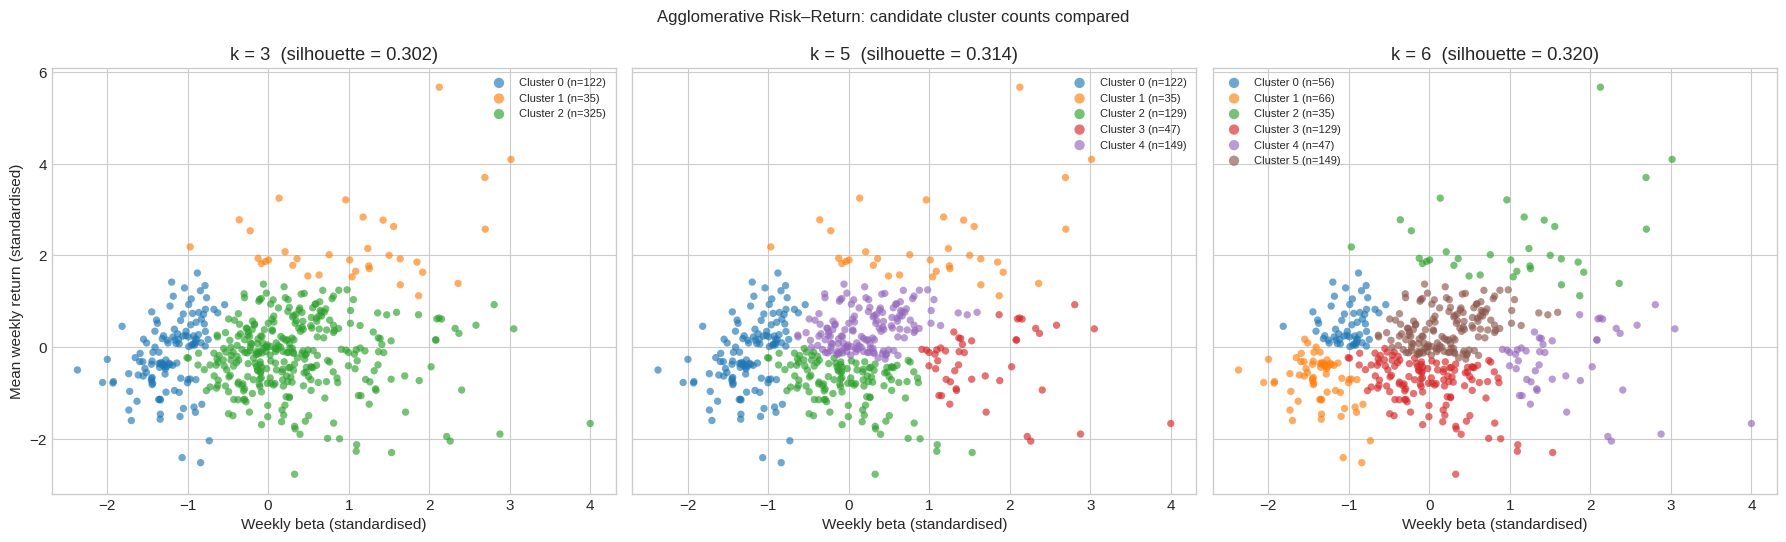

ARI between k=3 and k=5: 0.456
ARI between k=3 and k=6: 0.395
ARI between k=5 and k=6: 0.910


In [88]:
# 2.2.5 Compare Agglomerative Risk–Return profiles for candidate k values (3, 5, 6)
CANDIDATE_KS = [3, 5, 6]

# 1) Profile table in original units for each candidate k
rows = []
for k in CANDIDATE_KS:
    lbl = fcluster(Z_rr, t=k, criterion='maxclust') - 1
    prof = (
        rr_raw.assign(Cluster=lbl)
        .groupby('Cluster')
        .agg(
            n=('Weekly_Beta', 'size'),
            mean_weekly_return_pct=('Mean_Weekly_Return', lambda s: 100 * s.mean()),
            mean_beta=('Weekly_Beta', 'mean')
        )
        .round(3)
        .reset_index()
    )
    prof.insert(0, 'k', k)
    rows.append(prof)

profile_compare = pd.concat(rows, ignore_index=True)
display(profile_compare)

# 2) Scatter plots side by side (standardised axes), one panel per candidate k
fig, axes = plt.subplots(1, len(CANDIDATE_KS), figsize=(18, 5.5), sharex=True, sharey=True)
for ax, k in zip(axes, CANDIDATE_KS):
    lbl = fcluster(Z_rr, t=k, criterion='maxclust') - 1
    for c in sorted(set(lbl)):
        m = lbl == c
        ax.scatter(
            rr_sc['Weekly_Beta'].values[m],
            rr_sc['Mean_Weekly_Return'].values[m],
            color=PALETTE[c], alpha=0.65, s=28, edgecolors='none',
            label=f'Cluster {c} (n={m.sum()})'
        )
    sil = silhouette_score(rr_sc, lbl)
    ax.set_title(f'k = {k}  (silhouette = {sil:.3f})')
    ax.set_xlabel('Weekly beta (standardised)')
    ax.legend(fontsize=8, markerscale=1.4)
axes[0].set_ylabel('Mean weekly return (standardised)')
plt.suptitle('Agglomerative Risk–Return: candidate cluster counts compared', fontsize=12)
plt.tight_layout()
plt.show()

# 3) Partition stability across candidate k values (ARI)
for a, b in combinations(CANDIDATE_KS, 2):
    la = fcluster(Z_rr, t=a, criterion='maxclust') - 1
    lb = fcluster(Z_rr, t=b, criterion='maxclust') - 1
    print(f'ARI between k={a} and k={b}: {adjusted_rand_score(la, lb):.3f}')

K-Means — Risk–Return:
 k    inertia  silhouette  min_size                             sizes  feasible
 2 611.643572    0.376889       155                        [327, 155]     False
 3 441.995522    0.335377       119                   [190, 173, 119]      True
 4 357.667735    0.320261        51               [160, 146, 125, 51]      True
 5 289.353485    0.342908        37           [148, 129, 111, 57, 37]      True
 6 247.787818    0.332755        36        [134, 104, 84, 75, 49, 36]      True
 7 210.199093    0.360387        23     [139, 84, 74, 73, 52, 37, 23]     False
 8 187.540992    0.359775        21 [130, 76, 71, 68, 54, 38, 24, 21]     False

K-Means — RFM:
 k     inertia  silhouette  min_size                             sizes  feasible
 2 1055.668883    0.423826        68                         [414, 68]     False
 3  788.248134    0.326318        64                    [268, 150, 64]      True
 4  602.837892    0.341897        61                [210, 121, 90, 61]      Tr

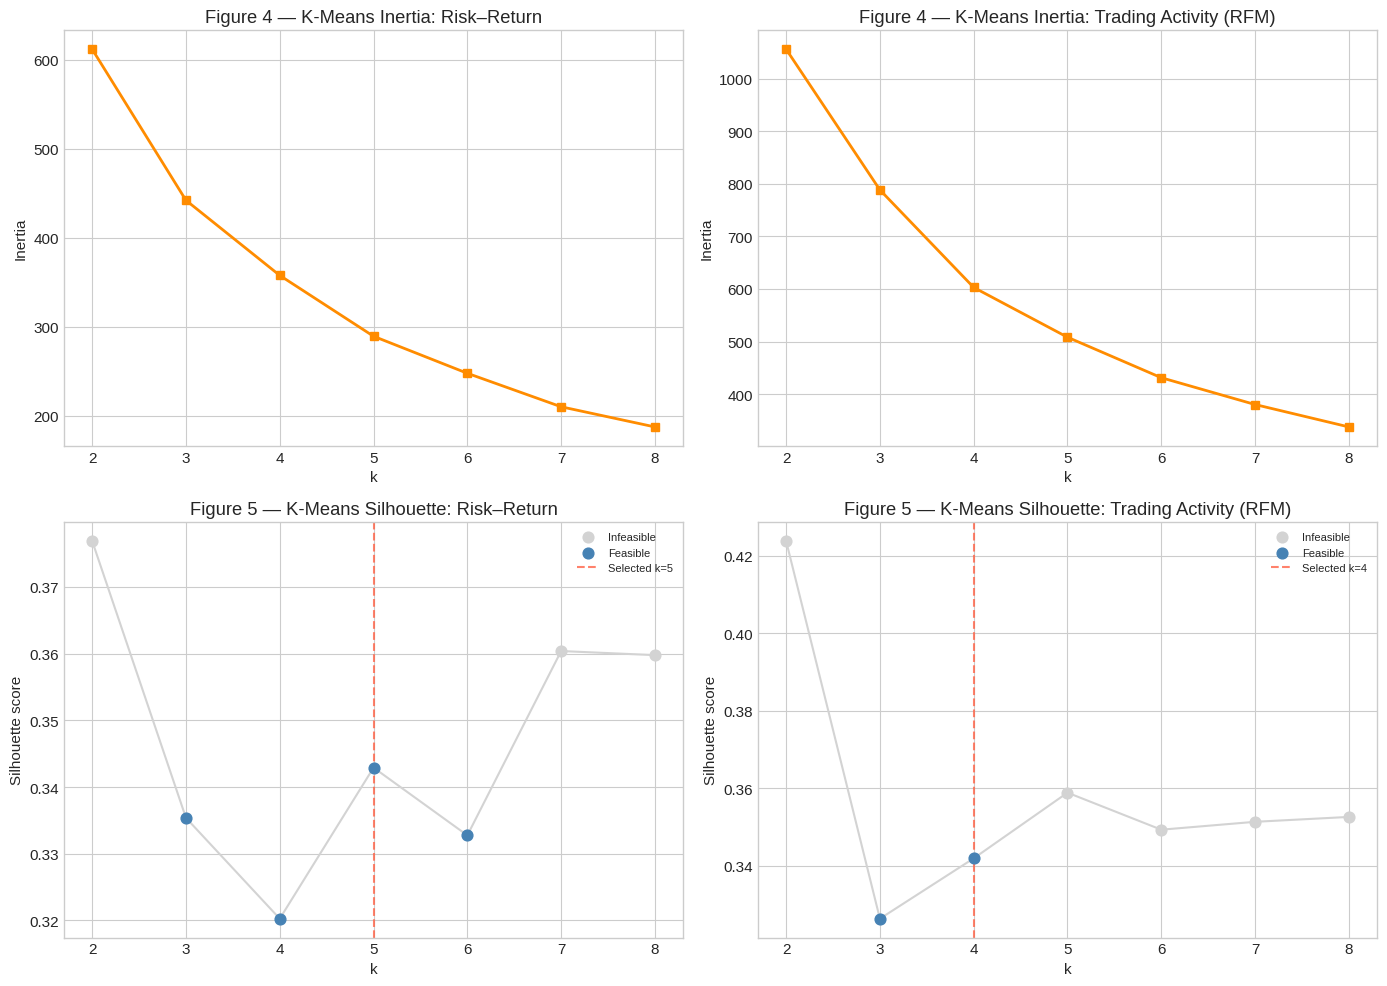

In [89]:
# 2.3.1a K-Means scan k=2 to 8 — same selection rule as Agglomerative
km_rr_results  = []
km_rfm_results = []

for k in K_RANGE:
    # Risk–Return
    km_rr       = KMeans(n_clusters=k, n_init=20, max_iter=500, random_state=RANDOM_STATE)
    lbls_rr     = km_rr.fit_predict(rr_sc)
    sizes_rr    = pd.Series(lbls_rr).value_counts().sort_values(ascending=False).tolist()
    feasible_rr = (k >= MIN_K) and (len(sizes_rr) == k) and (min(sizes_rr) / n_shares >= MIN_CLUSTER_SHARE)
    km_rr_results.append({
        'k': k, 'inertia': km_rr.inertia_,
        'silhouette': silhouette_score(rr_sc, lbls_rr),
        'min_size': min(sizes_rr), 'sizes': sizes_rr,
        'feasible': feasible_rr, 'labels': lbls_rr,
    })

    # RFM
    km_rfm       = KMeans(n_clusters=k, n_init=20, max_iter=500, random_state=RANDOM_STATE)
    lbls_rfm     = km_rfm.fit_predict(rfm_sc)
    sizes_rfm    = pd.Series(lbls_rfm).value_counts().sort_values(ascending=False).tolist()
    feasible_rfm = (k >= MIN_K) and (len(sizes_rfm) == k) and (min(sizes_rfm) / n_shares >= MIN_CLUSTER_SHARE)
    km_rfm_results.append({
        'k': k, 'inertia': km_rfm.inertia_,
        'silhouette': silhouette_score(rfm_sc, lbls_rfm),
        'min_size': min(sizes_rfm), 'sizes': sizes_rfm,
        'feasible': feasible_rfm, 'labels': lbls_rfm,
    })

km_rr_df  = pd.DataFrame(km_rr_results)
km_rfm_df = pd.DataFrame(km_rfm_results)

print("K-Means — Risk–Return:")
print(km_rr_df[['k', 'inertia', 'silhouette', 'min_size', 'sizes', 'feasible']].to_string(index=False))
print()
print("K-Means — RFM:")
print(km_rfm_df[['k', 'inertia', 'silhouette', 'min_size', 'sizes', 'feasible']].to_string(index=False))

best_rr_k_km,  best_rr_sil_km  = select_best_k(km_rr_df,  "K-Means Risk–Return")
best_rfm_k_km, best_rfm_sil_km = select_best_k(km_rfm_df, "K-Means RFM")

print(f"\nSelected k (K-Means, Risk–Return) : {best_rr_k_km}  (silhouette = {best_rr_sil_km:.3f})")
print(f"Selected k (K-Means, RFM)         : {best_rfm_k_km}  (silhouette = {best_rfm_sil_km:.3f})")

# Elbow + Silhouette plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, (km_df, best_k, title) in enumerate([
    (km_rr_df,  best_rr_k_km,  'Risk–Return'),
    (km_rfm_df, best_rfm_k_km, 'Trading Activity (RFM)'),
]):
    axes[0, col].plot(km_df['k'], km_df['inertia'], marker='s',
                      color='darkorange', linewidth=2)
    axes[0, col].set_title(f'Figure 4 — K-Means Inertia: {title}')
    axes[0, col].set_xlabel('k')
    axes[0, col].set_ylabel('Inertia')
    axes[0, col].set_xticks(list(K_RANGE))

    infeasible = km_df[~km_df['feasible']]
    feasible   = km_df[km_df['feasible']]
    axes[1, col].plot(km_df['k'], km_df['silhouette'],
                      color='lightgrey', linewidth=1.5, zorder=1)
    axes[1, col].scatter(infeasible['k'], infeasible['silhouette'],
                         color='lightgrey', s=60, label='Infeasible', zorder=2)
    axes[1, col].scatter(feasible['k'],   feasible['silhouette'],
                         color='steelblue', s=60, label='Feasible', zorder=3)
    axes[1, col].axvline(best_k, linestyle='--', color='tomato',
                         alpha=0.8, label=f'Selected k={best_k}')
    axes[1, col].set_title(f'Figure 5 — K-Means Silhouette: {title}')
    axes[1, col].set_xlabel('k')
    axes[1, col].set_ylabel('Silhouette score')
    axes[1, col].set_xticks(list(K_RANGE))
    axes[1, col].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [90]:
# 2.3.1b Sensitivity of selected k to the minimum-cluster-size threshold
res = {'Ward RR': agg_rr_df, 'Ward RFM': agg_rfm_df, 'KM RR': km_rr_df, 'KM RFM': km_rfm_df}
rows = []
for share in (0.02, 0.03, 0.04, 0.05, 0.06, 0.08):
    row = {'Min share': f'{share:.0%}'}
    for name, d in res.items():
        f = d[(d['k'] >= MIN_K) & (d['min_size'] >= share * n_shares)]
        row[name] = int(f.loc[f['silhouette'].idxmax(), 'k']) if len(f) else 'none'
    rows.append(row)
display(pd.DataFrame(rows))

,Min share,Ward RR,Ward RFM,KM RR,KM RFM
0,2%,6,6,7,5
1,3%,6,3,7,4
2,4%,6,3,7,4
3,5%,6,3,5,4
4,6%,6,3,5,4
5,8%,none,3,3,4


In [91]:
# 2.3.2 Final K-Means cluster labels
km_rr_labels  = km_rr_df.loc[km_rr_df['k']  == best_rr_k_km,  'labels'].values[0]
km_rfm_labels = km_rfm_df.loc[km_rfm_df['k'] == best_rfm_k_km, 'labels'].values[0]

print(f"K-Means RR cluster sizes (k={best_rr_k_km}):")
print(pd.Series(km_rr_labels).value_counts().sort_index())
print(f"\nK-Means RFM cluster sizes (k={best_rfm_k_km}):")
print(pd.Series(km_rfm_labels).value_counts().sort_index())

K-Means RR cluster sizes (k=5):
0    129
1     37
2    148
3     57
4    111
Name: count, dtype: int64

K-Means RFM cluster sizes (k=4):
0    210
1     61
2    121
3     90
Name: count, dtype: int64


2.4 Cluster Profiles and Algorithm Comparison

In [92]:
# 2.4.1 Cluster profiles — ORIGINAL (untransformed) units
print("=== Risk–Return Profiles — AGGLOMERATIVE ===")
display(
    rr_raw.assign(Cluster=agg_rr_labels)
    .groupby('Cluster')[['Mean_Weekly_Return', 'Weekly_Beta']]
    .agg(['mean', 'std', 'count']).round(5)
)

print("\n=== Risk–Return Profiles — K-MEANS ===")
display(
    rr_raw.assign(Cluster=km_rr_labels)
    .groupby('Cluster')[['Mean_Weekly_Return', 'Weekly_Beta']]
    .agg(['mean', 'std', 'count']).round(5)
)

print("\n=== RFM Profiles — AGGLOMERATIVE ===")
display(
    rfm_raw.assign(Cluster=agg_rfm_labels)
    .groupby('Cluster')[['Recency', 'Frequency', 'Monetary']]
    .agg(['mean', 'median', 'count']).round(2)
)

print("\n=== RFM Profiles — K-MEANS ===")
display(
    rfm_raw.assign(Cluster=km_rfm_labels)
    .groupby('Cluster')[['Recency', 'Frequency', 'Monetary']]
    .agg(['mean', 'median', 'count']).round(2)
)

=== Risk–Return Profiles — AGGLOMERATIVE ===


Mean_Weekly_Return                Weekly_Beta               
                      mean      std count        mean      std count
Cluster                                                             
0                  0.00418  0.00109    56     0.57682  0.08909    56
1                  0.00088  0.00144    66     0.43897  0.11889    66
2                  0.00876  0.00236    35     1.36656  0.36956    35
3                  0.00075  0.00138   129     0.95949  0.19111   129
4                  0.00196  0.00193    47     1.61968  0.25415    47
5                  0.00391  0.00111   149     1.05123  0.16636   149


=== Risk–Return Profiles — K-MEANS ===


Mean_Weekly_Return                Weekly_Beta               
                      mean      std count        mean      std count
Cluster                                                             
0                  0.00242  0.00153   129     0.52316  0.14445   129
1                  0.00862  0.00237    37     1.36423  0.35932    37
2                  0.00397  0.00116   148     1.02169  0.16084   148
3                  0.00201  0.00202    57     1.58015  0.25177    57
4                  0.00033  0.00143   111     0.95849  0.17940   111


=== RFM Profiles — AGGLOMERATIVE ===


Recency              Frequency                   Monetary  \
           mean median count      mean median count          mean   
Cluster                                                             
0         58.58   55.0    81      2.09    2.0    81  4.726754e+10   
1         13.68   11.0   154      2.86    3.0   154  8.014525e+10   
2         12.00   11.0   247      3.35    3.0   247  1.177795e+10   

                             
               median count  
Cluster                      
0        1.774056e+10    81  
1        3.969545e+10   154  
2        1.120162e+10   247


=== RFM Profiles — K-MEANS ===


Recency              Frequency                   Monetary  \
           mean median count      mean median count          mean   
Cluster                                                             
0         13.29   11.0   210      2.36    2.0   210  1.521436e+10   
1         66.02   55.0    61      1.67    2.0    61  5.618009e+10   
2         13.70   11.0   121      4.54    4.0   121  1.505907e+10   
3         14.91   11.0    90      3.23    3.0    90  1.181783e+11   

                             
               median count  
Cluster                      
0        1.333641e+10   210  
1        2.124212e+10    61  
2        1.286605e+10   121  
3        6.143893e+10    90

In [93]:
# 2.4.2 GICS Sector Composition & Representative Tickers per Cluster
def sector_and_sample_summary(df_meta, labels, model_name, n_examples=4):
    temp = df_meta[['Security', 'GICS Sector']].copy()
    temp['Cluster'] = labels
    sector_pct = (pd.crosstab(temp['Cluster'], temp['GICS Sector'], normalize='index') * 100).round(1)
    top_sectors = sector_pct.apply(
        lambda r: ', '.join([f"{sec} ({val:.1f}%)" for sec, val in r.nlargest(3).items() if val > 0]),
        axis=1
    ).rename('Top 3 GICS Sectors')
    samples = temp.groupby('Cluster').apply(
        lambda g: ', '.join(g.index[:n_examples].tolist()),
        include_groups=False
    ).rename('Example Tickers')
    sizes = temp.groupby('Cluster').size().rename('n')
    print(f"=== {model_name}: Sector Concentration & Representative Tickers ===")
    display(pd.concat([sizes, top_sectors, samples], axis=1))

sector_and_sample_summary(df, agg_rr_labels,  f"Agglomerative Risk–Return (k={best_rr_k_agg})")
sector_and_sample_summary(df, km_rr_labels,   f"K-Means Risk–Return (k={best_rr_k_km})")
sector_and_sample_summary(df, agg_rfm_labels, f"Agglomerative RFM (k={best_rfm_k_agg})")
sector_and_sample_summary(df, km_rfm_labels,  f"K-Means RFM (k={best_rfm_k_km})")

=== Agglomerative Risk–Return (k=6): Sector Concentration & Representative Tickers ===


,n,Top 3 GICS Sectors,Example Tickers
Cluster,,,
0,56,"Financials (28.6%), Energy (17.9%), Utilities ...","ABBV, AFL, ALL, ACGL"
1,66,"Consumer Staples (33.3%), Health Care (28.8%),...","ABT, LNT, MO, AEE"
2,35,"Information Technology (37.1%), Industrials (2...","APO, ARES, ANET, AXON"
3,129,"Industrials (21.7%), Health Care (16.3%), Real...","MMM, AOS, AES, A"
4,47,"Information Technology (48.9%), Consumer Discr...","ADBE, AMD, ABNB, ALB"
5,149,"Financials (23.5%), Industrials (22.1%), Infor...","ACN, GOOGL, GOOG, AXP"


=== K-Means Risk–Return (k=5): Sector Concentration & Representative Tickers ===


,n,Top 3 GICS Sectors,Example Tickers
Cluster,,,
0,129,"Utilities (19.4%), Consumer Staples (18.6%), H...","ABT, ABBV, APD, LNT"
1,37,"Information Technology (37.8%), Industrials (1...","APO, ARES, ANET, AXON"
2,148,"Financials (23.6%), Industrials (22.3%), Infor...","ACN, AFL, GOOGL, GOOG"
3,57,"Information Technology (47.4%), Consumer Discr...","ADBE, AMD, ABNB, ALB"
4,111,"Industrials (20.7%), Health Care (18.9%), Real...","MMM, AOS, AES, A"


=== Agglomerative RFM (k=3): Sector Concentration & Representative Tickers ===


,n,Top 3 GICS Sectors,Example Tickers
Cluster,,,
0,81,"Information Technology (22.2%), Financials (12...","AES, APD, AKAM, LNT"
1,154,"Information Technology (20.1%), Financials (16...","MMM, ABT, ABBV, ACN"
2,247,"Industrials (20.2%), Financials (15.4%), Healt...","AOS, AFL, A, ALB"


=== K-Means RFM (k=4): Sector Concentration & Representative Tickers ===


,n,Top 3 GICS Sectors,Example Tickers
Cluster,,,
0,210,"Industrials (20.5%), Financials (15.7%), Infor...","AOS, ABT, AFL, A"
1,61,"Information Technology (21.3%), Utilities (14....","AES, APD, AKAM, LNT"
2,121,"Industrials (19.0%), Financials (15.7%), Healt...","MMM, ALGN, AMCR, AEE"
3,90,"Information Technology (27.8%), Health Care (1...","ABBV, ACN, ADBE, AMD"


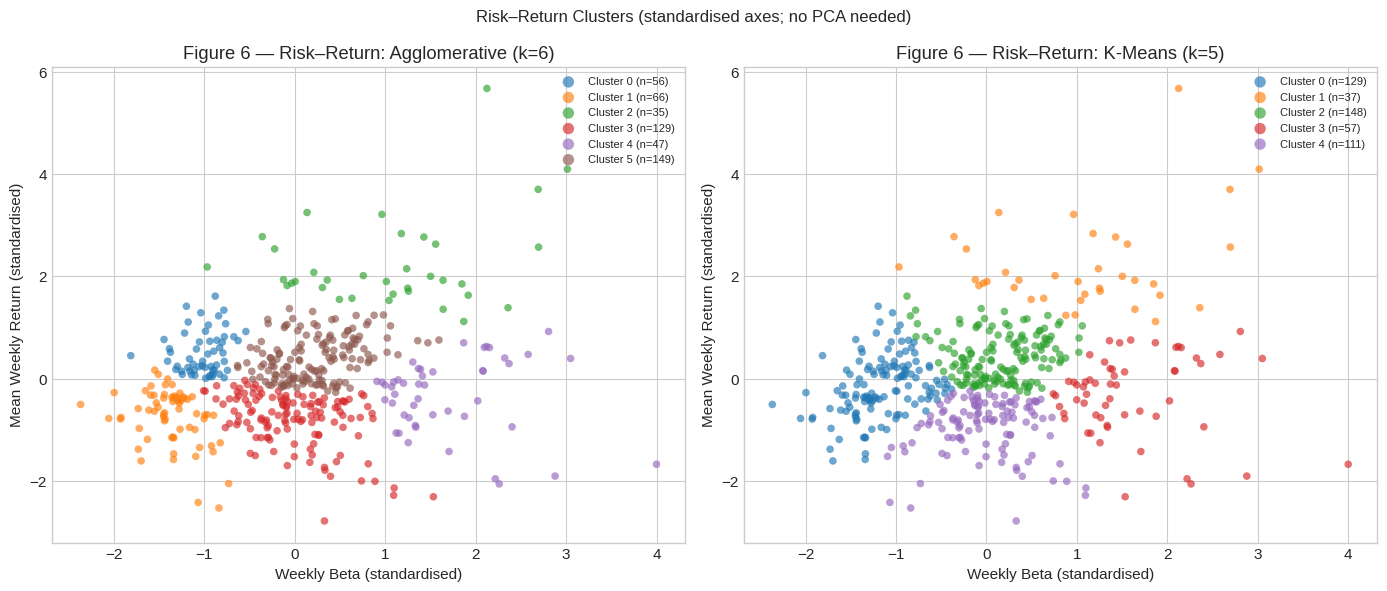

PCA explained variance: PC1=46.0%, PC2=33.7%, Total=79.7%
PCA component loadings:
     Recency  Frequency  log1p_Monetary
PC1    0.712     -0.653           0.258
PC2    0.029      0.394           0.919


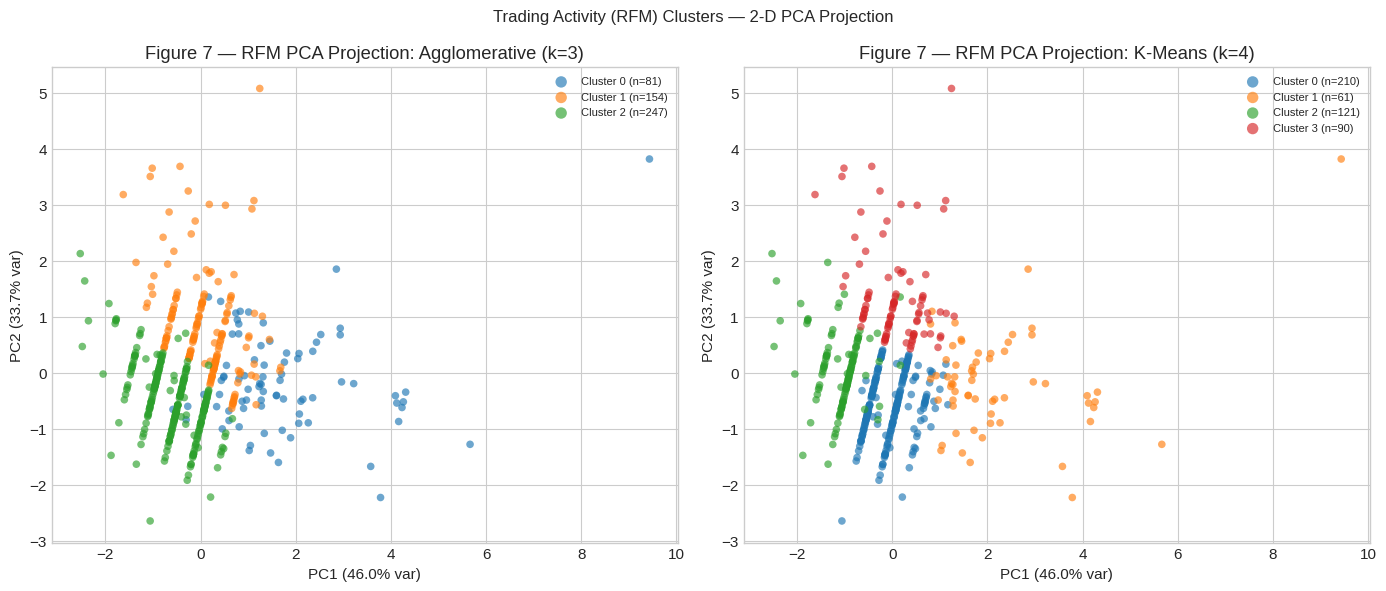

In [94]:
# 2.4.3 Labelled 2-D visualisations (each algorithm at its own selected k)
# Risk–Return: already 2-D — plot directly on standardised axes (no PCA needed)
# RFM: 3 features -> PCA to 2 components

# --- Risk–Return scatter ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, labels, title in [
    (axes[0], agg_rr_labels, f'Agglomerative (k={best_rr_k_agg})'),
    (axes[1], km_rr_labels,  f'K-Means (k={best_rr_k_km})'),
]:
    for c in sorted(set(labels)):
        mask = labels == c
        ax.scatter(
            rr_sc['Weekly_Beta'].values[mask],
            rr_sc['Mean_Weekly_Return'].values[mask],
            label=f'Cluster {c} (n={mask.sum()})', color=PALETTE[c],
            alpha=0.65, s=30, edgecolors='none'
        )
    ax.set_xlabel('Weekly Beta (standardised)')
    ax.set_ylabel('Mean Weekly Return (standardised)')
    ax.set_title(f'Figure 6 — Risk–Return: {title}')
    ax.legend(fontsize=8, markerscale=1.5)
plt.suptitle('Risk–Return Clusters (standardised axes; no PCA needed)', fontsize=12)
plt.tight_layout()
plt.show()

# --- RFM PCA scatter ---
pca = PCA(n_components=2, random_state=RANDOM_STATE)
rfm_pca   = pca.fit_transform(rfm_sc)
explained = pca.explained_variance_ratio_

print(f"PCA explained variance: PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, Total={sum(explained):.1%}")
print("PCA component loadings:")
print(pd.DataFrame(pca.components_, columns=rfm_sc.columns, index=['PC1', 'PC2']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, labels, title in [
    (axes[0], agg_rfm_labels, f'Agglomerative (k={best_rfm_k_agg})'),
    (axes[1], km_rfm_labels,  f'K-Means (k={best_rfm_k_km})'),
]:
    for c in sorted(set(labels)):
        mask = labels == c
        ax.scatter(
            rfm_pca[mask, 0], rfm_pca[mask, 1],
            label=f'Cluster {c} (n={mask.sum()})', color=PALETTE[c],
            alpha=0.65, s=30, edgecolors='none'
        )
    ax.set_xlabel(f'PC1 ({explained[0]:.1%} var)')
    ax.set_ylabel(f'PC2 ({explained[1]:.1%} var)')
    ax.set_title(f'Figure 7 — RFM PCA Projection: {title}')
    ax.legend(fontsize=8, markerscale=1.5)
plt.suptitle('Trading Activity (RFM) Clusters — 2-D PCA Projection', fontsize=12)
plt.tight_layout()
plt.show()

ALGORITHM COMPARISON (SELECTED FEASIBLE k)
  Metric                               RR       RFM
  Adjusted Rand Index (selected k)    0.685    0.319
  Agg silhouette (selected k)         0.320    0.305
  KM  silhouette (selected k)         0.343    0.342
  Agg selected k                          6        3
  KM  selected k                          5        4
  ARI RR : 0.685  -> MODERATE agreement — boundary assignments differ; core clusters agree.
  ARI RFM: 0.319  -> LOW agreement — the two methods impose different structures.
  [Note] RR selected k differs (Agg=6 vs KM=5) — ARI partly reflects the k mismatch.
  [Note] RFM selected k differs (Agg=3 vs KM=4) — ARI partly reflects the k mismatch.

View 2 — ARI at matched k (k = 3 to 6):
 k  ARI_RR  ARI_RFM
 3   0.242    0.829
 4   0.390    0.342
 5   0.744    0.398
 6   0.753    0.530

Risk–Return — inertia and % drop from the previous k:
 k  inertia  drop_%
 2    611.6     NaN
 3    442.0    27.7
 4    357.7    19.1
 5    289.4    19.1

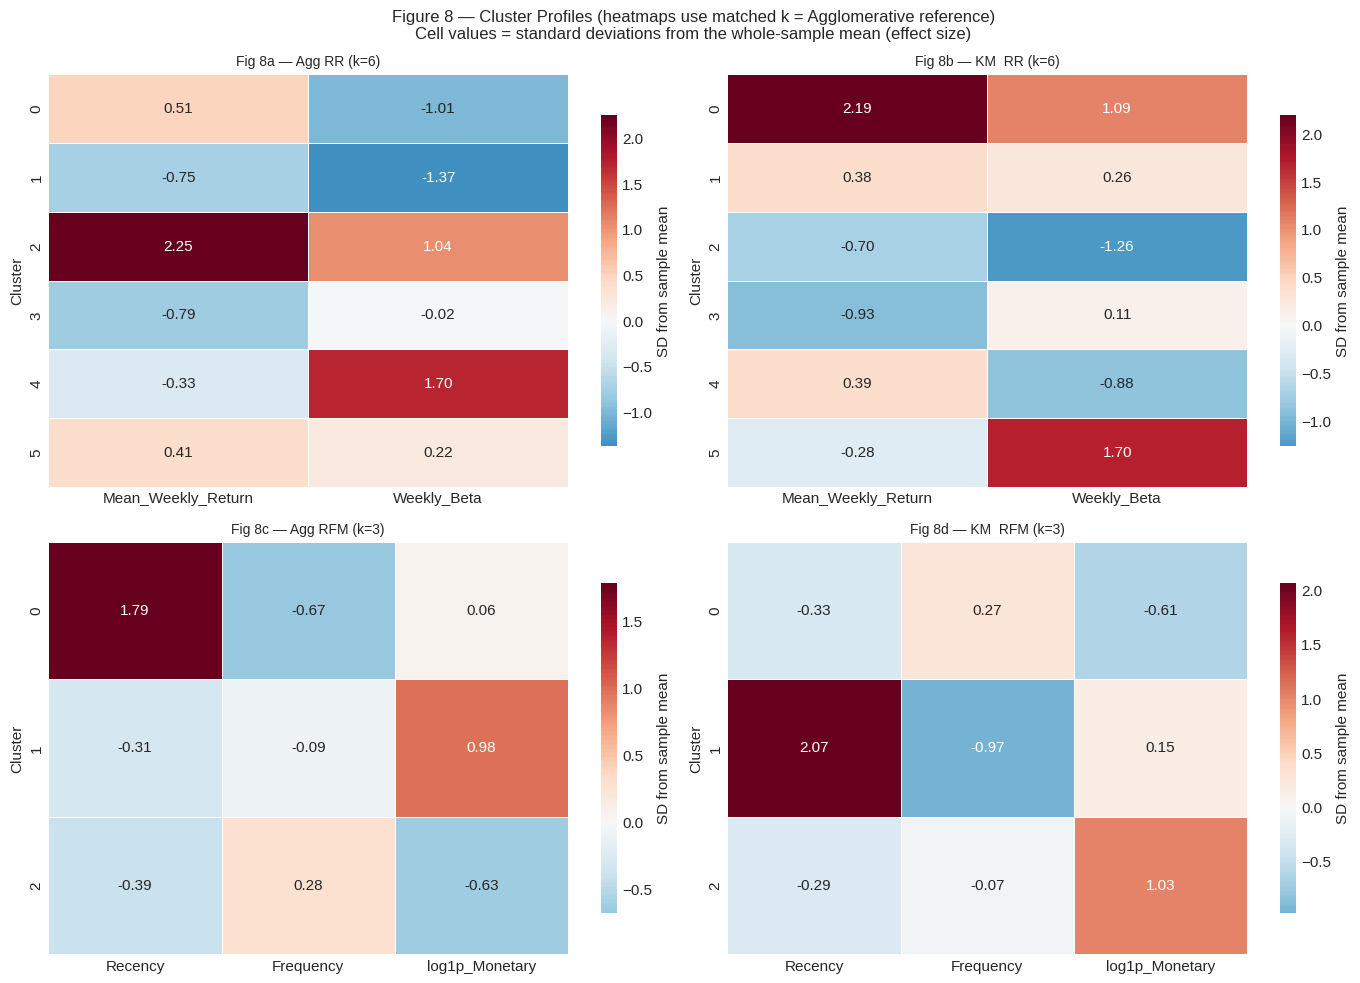

Note: scatter plots (Figures 6 and 7) use each algorithm's own selected k.
Heatmaps use matched k so profiles are directly comparable between algorithms.


In [95]:
# 2.4.4 Algorithm comparison — selected-k summary, matched-k ARI, inertia & profile heatmaps

# ── View 1: Summary & ARI at each algorithm's own selected k ──────────────
ari_rr_own  = adjusted_rand_score(agg_rr_labels,  km_rr_labels)
ari_rfm_own = adjusted_rand_score(agg_rfm_labels, km_rfm_labels)

print("=" * 62)
print("ALGORITHM COMPARISON (SELECTED FEASIBLE k)")
print("=" * 62)
print(f"  Metric                               RR       RFM")
print(f"  Adjusted Rand Index (selected k)   {ari_rr_own:>6.3f}   {ari_rfm_own:>6.3f}")
print(f"  Agg silhouette (selected k)        {best_rr_sil_agg:>6.3f}   {best_rfm_sil_agg:>6.3f}")
print(f"  KM  silhouette (selected k)        {best_rr_sil_km:>6.3f}   {best_rfm_sil_km:>6.3f}")
print(f"  Agg selected k                     {best_rr_k_agg:>6}   {best_rfm_k_agg:>6}")
print(f"  KM  selected k                     {best_rr_k_km:>6}   {best_rfm_k_km:>6}")
print("=" * 62)

def interpret_ari(ari, label):
    if ari >= 0.7:
        msg = "HIGH agreement — both algorithms recover the same structure."
    elif ari >= 0.4:
        msg = "MODERATE agreement — boundary assignments differ; core clusters agree."
    else:
        msg = "LOW agreement — the two methods impose different structures."
    print(f"  ARI {label}: {ari:.3f}  -> {msg}")

interpret_ari(ari_rr_own,  "RR ")
interpret_ari(ari_rfm_own, "RFM")

if best_rr_k_agg != best_rr_k_km:
    print("  [Note] RR selected k differs (Agg=6 vs KM=5) — ARI partly reflects the k mismatch.")
if best_rfm_k_agg != best_rfm_k_km:
    print("  [Note] RFM selected k differs (Agg=3 vs KM=4) — ARI partly reflects the k mismatch.")

# ── View 2: ARI at matched k (k = 3 to 6) ─────────────────────────────────
print("\nView 2 — ARI at matched k (k = 3 to 6):")
ari_rows = []
for k in range(3, 7):
    lbls_agg_rr  = fcluster(Z_rr,  t=k, criterion='maxclust') - 1
    lbls_km_rr   = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(rr_sc)
    lbls_agg_rfm = fcluster(Z_rfm, t=k, criterion='maxclust') - 1
    lbls_km_rfm  = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(rfm_sc)
    ari_rows.append({
        'k':       k,
        'ARI_RR':  round(adjusted_rand_score(lbls_agg_rr,  lbls_km_rr),  3),
        'ARI_RFM': round(adjusted_rand_score(lbls_agg_rfm, lbls_km_rfm), 3),
    })
ari_table = pd.DataFrame(ari_rows)
print(ari_table.to_string(index=False))

# ── Inertia (elbow) drop summary ──────────────────────────────────────────
for name, df_ in [('Risk–Return', km_rr_df), ('RFM', km_rfm_df)]:
    drop_pct = (-df_['inertia'].diff() / df_['inertia'].shift(1) * 100).round(1)
    print(f"\n{name} — inertia and % drop from the previous k:")
    print(pd.DataFrame({'k': df_['k'], 'inertia': df_['inertia'].round(1),
                        'drop_%': drop_pct}).to_string(index=False))

print(f"""
Note on the inertia (elbow) plots:
Risk–Return: inertia declines gradually with no clear elbow.
RFM: inertia drops by 25.3% at k=3, 23.5% at k=4, and 15.7% at k=5, showing only a mild bend rather than a sharp elbow.
Because the elbow is not clear-cut, k was chosen using silhouette scores,
the minimum cluster-size rule (k >= {MIN_K}, min {MIN_CLUSTER_SHARE:.0%} per cluster)
and the interpretability of the resulting profiles, with inertia as
supporting evidence.
""")

# ── Profile heatmap — matched k (Agglomerative k as reference) ────────────
matched_k_rr  = best_rr_k_agg
matched_k_rfm = best_rfm_k_agg

agg_rr_labels_matched  = fcluster(Z_rr,  t=matched_k_rr,  criterion='maxclust') - 1
agg_rfm_labels_matched = fcluster(Z_rfm, t=matched_k_rfm, criterion='maxclust') - 1
km_rr_labels_matched   = KMeans(n_clusters=matched_k_rr,  n_init=20, random_state=RANDOM_STATE).fit_predict(rr_sc)
km_rfm_labels_matched  = KMeans(n_clusters=matched_k_rfm, n_init=20, random_state=RANDOM_STATE).fit_predict(rfm_sc)

# Heatmaps use log1p(Monetary) so extreme mega-caps do not distort cluster means
rfm_heat = rfm_raw.copy()
rfm_heat['log1p_Monetary'] = np.log1p(rfm_heat['Monetary'])
rfm_heat_cols = ['Recency', 'Frequency', 'log1p_Monetary']

def make_profile_heatmap(raw_df, labels, feat_cols, title, ax):
    """Effect size: cluster mean vs whole-sample mean, in sample SDs."""
    sample_mean = raw_df[feat_cols].mean()
    sample_std  = raw_df[feat_cols].std()
    profile     = raw_df[feat_cols].assign(Cluster=labels).groupby('Cluster')[feat_cols].mean()
    effect_size = (profile - sample_mean) / sample_std
    sns.heatmap(effect_size, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, linewidths=0.5, ax=ax,
                cbar_kws={'shrink': 0.8, 'label': 'SD from sample mean'})
    ax.set_title(title, fontsize=10)
    ax.set_ylabel('Cluster')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
make_profile_heatmap(rr_raw,   agg_rr_labels_matched,  ['Mean_Weekly_Return', 'Weekly_Beta'],
                     f'Fig 8a — Agg RR (k={matched_k_rr})',   axes[0, 0])
make_profile_heatmap(rr_raw,   km_rr_labels_matched,   ['Mean_Weekly_Return', 'Weekly_Beta'],
                     f'Fig 8b — KM  RR (k={matched_k_rr})',   axes[0, 1])
make_profile_heatmap(rfm_heat, agg_rfm_labels_matched, rfm_heat_cols,
                     f'Fig 8c — Agg RFM (k={matched_k_rfm})', axes[1, 0])
make_profile_heatmap(rfm_heat, km_rfm_labels_matched,  rfm_heat_cols,
                     f'Fig 8d — KM  RFM (k={matched_k_rfm})', axes[1, 1])

plt.suptitle(
    'Figure 8 — Cluster Profiles (heatmaps use matched k = Agglomerative reference)\n'
    'Cell values = standard deviations from the whole-sample mean (effect size)',
    fontsize=12
)
plt.tight_layout()
plt.show()
print("Note: scatter plots (Figures 6 and 7) use each algorithm's own selected k.")
print("Heatmaps use matched k so profiles are directly comparable between algorithms.")

2.5 RFM Sensitivity and Correlated Inputs

Pearson Correlation — Raw RFM:


,Recency,Frequency,Monetary
Recency,1.000,-0.354,0.300
Frequency,-0.354,1.000,0.015
Monetary,0.300,0.015,1.000


Pearson Correlation — Transformed RFM (with log1p_Monetary):


,Recency,Frequency,log1p_Monetary
Recency,1.000,-0.354,0.152
Frequency,-0.354,1.000,0.016
log1p_Monetary,0.152,0.016,1.000


Spearman Rank Correlation — Transformed RFM:


,Recency,Frequency,log1p_Monetary
Recency,1.000,-0.203,0.137
Frequency,-0.203,1.000,-0.045
log1p_Monetary,0.137,-0.045,1.000


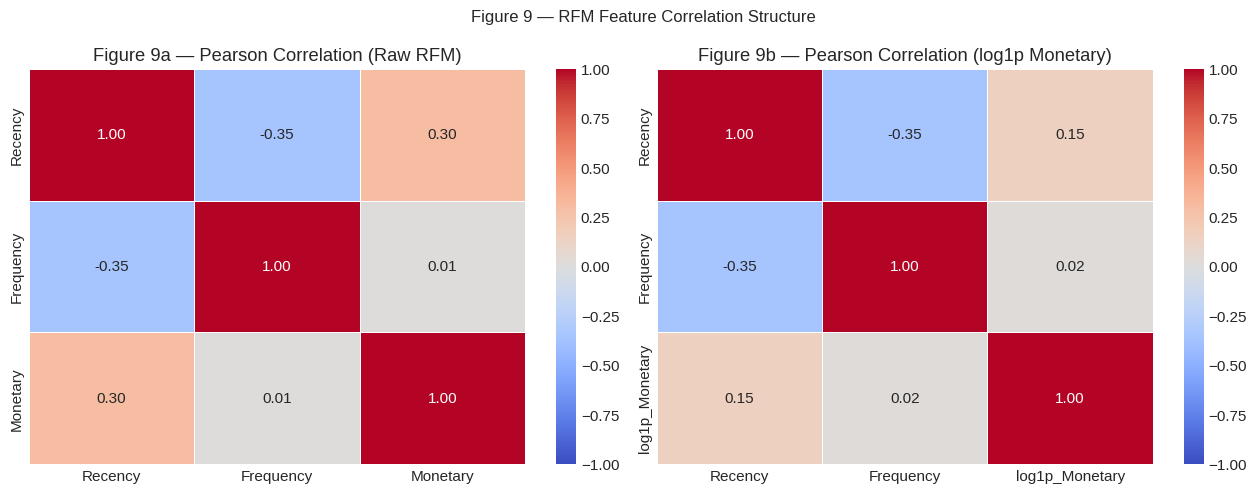

In [96]:
# 2.5.1 Correlation and multicollinearity check among RFM inputs
rfm_corr_raw = rfm_raw[['Recency', 'Frequency', 'Monetary']].corr(method='pearson')
rfm_corr_tf  = rfm_tf[['Recency', 'Frequency', 'log1p_Monetary']].corr(method='pearson')
rfm_corr_sp  = rfm_tf[['Recency', 'Frequency', 'log1p_Monetary']].corr(method='spearman')

print("Pearson Correlation — Raw RFM:")
display(rfm_corr_raw.round(3))

print("Pearson Correlation — Transformed RFM (with log1p_Monetary):")
display(rfm_corr_tf.round(3))

print("Spearman Rank Correlation — Transformed RFM:")
display(rfm_corr_sp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(rfm_corr_raw, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            center=0, linewidths=0.5, ax=axes[0])
axes[0].set_title('Figure 9a — Pearson Correlation (Raw RFM)')

sns.heatmap(rfm_corr_tf, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            center=0, linewidths=0.5, ax=axes[1])
axes[1].set_title('Figure 9b — Pearson Correlation (log1p Monetary)')

plt.suptitle('Figure 9 — RFM Feature Correlation Structure', fontsize=12)
plt.tight_layout()
plt.show()

In [97]:
# 2.5.2 Removal of Monetary — repeat Ward solution with Recency & Frequency only

# Step 1: Standardise R+F afresh — do NOT reuse the 3-feature scaler
rf_raw    = rfm_raw[['Recency', 'Frequency']].copy()
scaler_rf = StandardScaler()
rf_sc     = pd.DataFrame(
    scaler_rf.fit_transform(rf_raw),
    index=rf_raw.index, columns=rf_raw.columns
)

print("R+F standardised — mean and std:")
print(rf_sc.agg(['mean', 'std']).round(6))

# Step 2: Ward linkage and cut at same k as full RFM solution
Z_rf      = linkage(rf_sc, method='ward', metric='euclidean')
rf_labels = fcluster(Z_rf, t=best_rfm_k_agg, criterion='maxclust') - 1

print(f"\nR+F cluster sizes (k={best_rfm_k_agg}, same k as full RFM solution):")
print(pd.Series(rf_labels).value_counts().sort_index())

# Step 3: Silhouette — with explicit incomparability warning
sil_rf       = silhouette_score(rf_sc,  rf_labels)
sil_rfm_full = silhouette_score(rfm_sc, agg_rfm_labels)

print(f"\nSilhouette — full RFM (3 features) : {sil_rfm_full:.3f}")
print(f"Silhouette — R+F only (2 features) : {sil_rf:.3f}")
print("""
NOTE — these silhouette scores are computed in different feature spaces
(3-D vs 2-D) and are therefore NOT directly comparable. A higher
silhouette in the 2-feature space does not mean R+F clusters are
'better'; it reflects that distances in a lower-dimensional space are
easier to separate. Use ARI (below) to compare membership agreement.
""")

# Step 4: Adjusted Rand Index — unaffected by arbitrary cluster numbering
ari_rfm_vs_rf = adjusted_rand_score(agg_rfm_labels, rf_labels)

print("=" * 55)
print("SENSITIVITY TEST — Removal of Monetary (M)")
print("=" * 55)
print(f"  Cluster count (k)                : {best_rfm_k_agg}")
print(f"  ARI (full RFM vs. R+F only)      : {ari_rfm_vs_rf:.3f}")
print("=" * 55)

# Step 5: Profile both solutions and cross-tabulate memberships
rfm_profile = (rfm_raw.assign(RFM_Cluster=agg_rfm_labels)
               .groupby('RFM_Cluster')[['Recency', 'Frequency', 'Monetary']].mean())
rf_profile  = (rfm_raw.assign(RF_Cluster=rf_labels)
               .groupby('RF_Cluster')[['Recency', 'Frequency', 'Monetary']].mean())

print("\nFull RFM cluster means (original units):")
print(rfm_profile.round(2))
print("\nR+F-only cluster means (Monetary shown for reference only):")
print(rf_profile.round(2))

print("\nCross-tabulation (rows = full RFM clusters, columns = R+F-only clusters):")
display(pd.crosstab(
    pd.Series(agg_rfm_labels, name='Full RFM'),
    pd.Series(rf_labels, name='R+F only')
))

R+F standardised — mean and std:
       Recency  Frequency
mean -0.000000  -0.000000
std   1.001039   1.001039

R+F cluster sizes (k=3, same k as full RFM solution):
0     82
1    125
2    275
Name: count, dtype: int64

Silhouette — full RFM (3 features) : 0.305
Silhouette — R+F only (2 features) : 0.489

NOTE — these silhouette scores are computed in different feature spaces
(3-D vs 2-D) and are therefore NOT directly comparable. A higher
silhouette in the 2-feature space does not mean R+F clusters are
'better'; it reflects that distances in a lower-dimensional space are
easier to separate. Use ARI (below) to compare membership agreement.

SENSITIVITY TEST — Removal of Monetary (M)
  Cluster count (k)                : 3
  ARI (full RFM vs. R+F only)      : 0.264

Full RFM cluster means (original units):
             Recency  Frequency      Monetary
RFM_Cluster                                  
0              58.58       2.09  4.726754e+10
1              13.68       2.86  8.014525e+10


R+F only,0,1,2
Full RFM,,,
0,73,0,8
1,9,59,86
2,0,66,181



Monetary profile — Full RFM clusters:
            mean   median      min        max  count
Cluster                                             
0        $47.3bn  $17.7bn   $4.4bn  $1825.3bn     81
1        $80.1bn  $39.7bn  $18.7bn  $1847.7bn    154
2        $11.8bn  $11.2bn   $1.3bn    $37.9bn    247

Monetary profile — R+F only clusters:
            mean   median     min        max  count
Cluster                                            
0        $48.1bn  $20.5bn  $4.4bn  $1825.3bn     82
1        $34.3bn  $17.7bn  $3.7bn   $623.3bn    125
2        $39.4bn  $15.0bn  $1.3bn  $1847.7bn    275

Cluster mean Monetary range:
  Full RFM clusters   : $68.4bn spread across cluster means
  R+F-only clusters   : $13.8bn spread across cluster means

Interpretation: The R+F-only clusters show a substantially smaller spread in mean Monetary than the full RFM clusters. This confirms that log1p(M) was providing genuine additional discrimination — separating high-value liquid stocks from smaller 

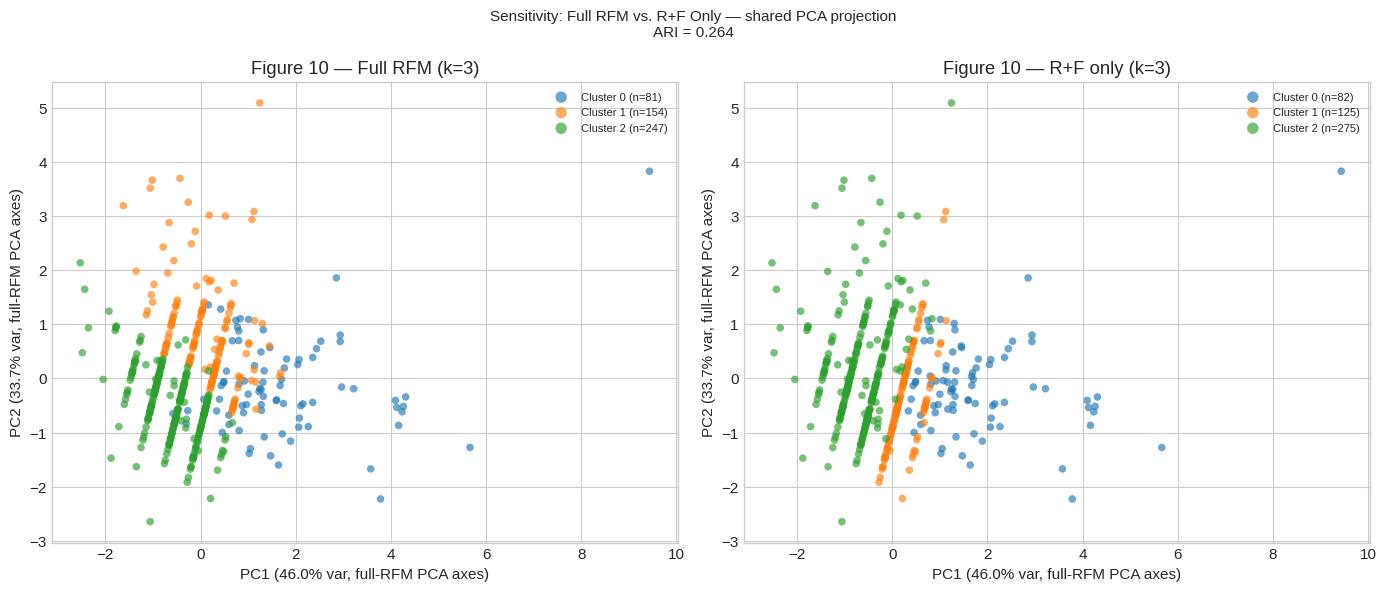

In [98]:
# 2.5.3 Traded-value profiles and shared-PCA visualisation
def monetary_profile_table(labels, label_name):
    tbl = (
        rfm_raw[['Monetary']].assign(Cluster=labels)
        .groupby('Cluster')['Monetary']
        .agg(['mean', 'median', 'min', 'max', 'count'])
    )
    tbl_disp = tbl.copy()
    for col in ['mean', 'median', 'min', 'max']:
        tbl_disp[col] = tbl_disp[col].apply(lambda x: f"${x/1e9:.1f}bn")
    print(f"\nMonetary profile — {label_name}:")
    print(tbl_disp.to_string())
    return tbl

mv_full = monetary_profile_table(agg_rfm_labels, "Full RFM clusters")
mv_rf   = monetary_profile_table(rf_labels,      "R+F only clusters")

mv_full_range = mv_full['mean'].max() - mv_full['mean'].min()
mv_rf_range   = mv_rf['mean'].max()   - mv_rf['mean'].min()

print(f"""
Cluster mean Monetary range:
  Full RFM clusters   : ${mv_full_range/1e9:.1f}bn spread across cluster means
  R+F-only clusters   : ${mv_rf_range/1e9:.1f}bn spread across cluster means
""")

if mv_rf_range < 0.5 * mv_full_range:
    m_conclusion = (
        "The R+F-only clusters show a substantially smaller spread in mean Monetary "
        "than the full RFM clusters. This confirms that log1p(M) was providing genuine "
        "additional discrimination — separating high-value liquid stocks from smaller "
        "peers that trade with similar timing and frequency."
    )
else:
    m_conclusion = (
        "The R+F-only clusters retain a similar spread in mean Monetary to the full RFM "
        "clusters. This suggests that activity patterns (R, F) already correlate strongly "
        "with traded value — log1p(M) was largely redundant."
    )

print(f"Interpretation: {m_conclusion}")

# Visualisation: full RFM vs R+F only on shared PCA axes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, labels, title in [
    (axes[0], agg_rfm_labels, f'Full RFM (k={best_rfm_k_agg})'),
    (axes[1], rf_labels,      f'R+F only (k={best_rfm_k_agg})'),
]:
    for c in sorted(set(labels)):
        mask = labels == c
        ax.scatter(
            rfm_pca[mask, 0], rfm_pca[mask, 1],
            label=f'Cluster {c} (n={mask.sum()})', color=PALETTE[c],
            alpha=0.65, s=30, edgecolors='none'
        )
    ax.set_xlabel(f'PC1 ({explained[0]:.1%} var, full-RFM PCA axes)')
    ax.set_ylabel(f'PC2 ({explained[1]:.1%} var, full-RFM PCA axes)')
    ax.set_title(f'Figure 10 — {title}')
    ax.legend(fontsize=8, markerscale=1.5)
plt.suptitle(
    f'Sensitivity: Full RFM vs. R+F Only — shared PCA projection\n'
    f'ARI = {ari_rfm_vs_rf:.3f}',
    fontsize=11
)
plt.tight_layout()
plt.show()

Additional charts

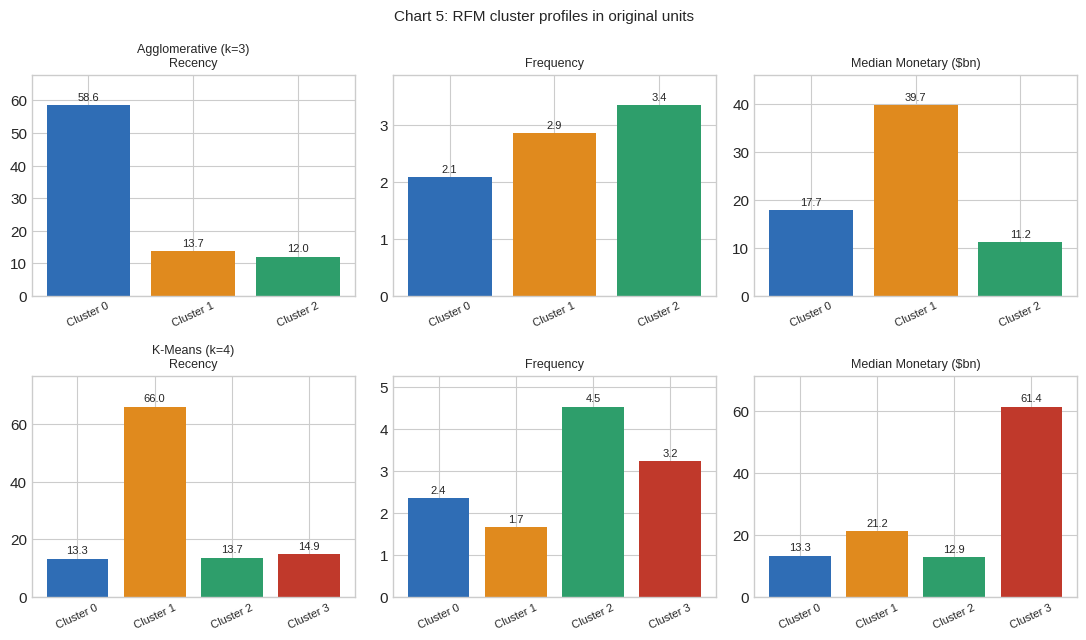

In [99]:
# 2.7.4 Chart 5 — RFM cluster profiles in original units
cols = ['#2f6db5', '#e08a1e', '#2e9e6b', '#c0392b', '#8e5bb5', '#6b6b6b']

def _rfm_bar_profile(labels):
    g = rfm_raw.assign(Cluster=labels).groupby('Cluster')
    return pd.DataFrame({'Recency': g['Recency'].mean(),
                         'Frequency': g['Frequency'].mean(),
                         'Median Monetary ($bn)': g['Monetary'].median() / 1e9})

sets = [(f'Agglomerative (k={best_rfm_k_agg})', _rfm_bar_profile(agg_rfm_labels)),
        (f'K-Means (k={best_rfm_k_km})',        _rfm_bar_profile(km_rfm_labels))]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for r, (name, prof) in enumerate(sets):
    for c, col in enumerate(prof.columns):
        ax = axes[r, c]
        bars = ax.bar([f'Cluster {i}' for i in prof.index], prof[col],
                      color=cols[:len(prof)])
        ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2)
        ax.margins(y=0.16)
        ax.set_title(f'{name}\n{col}' if c == 0 else col, fontsize=9)
        ax.tick_params(axis='x', labelrotation=25, labelsize=8)
fig.suptitle('Chart 5: RFM cluster profiles in original units', fontsize=11)
fig.tight_layout()
fig.savefig('chart5_rfm_profiles.png', dpi=300)
plt.show()

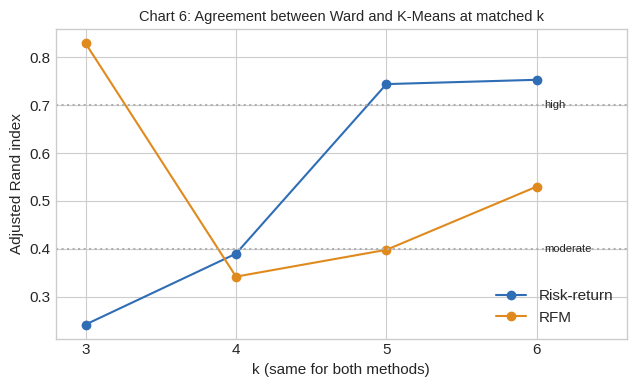

In [100]:
# 2.7.5 Chart 6 — ARI at matched k
# ari_table is created in the matched-k ARI cell (cell 24)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ari_table['k'], ari_table['ARI_RR'],  marker='o', color='#2f6db5', label='Risk-return')
ax.plot(ari_table['k'], ari_table['ARI_RFM'], marker='o', color='#e08a1e', label='RFM')
ax.axhline(.7, ls=':', color='#b0b0b0')
ax.axhline(.4, ls=':', color='#b0b0b0')
ax.text(6.05, .7, 'high', va='center', fontsize=8)
ax.text(6.05, .4, 'moderate', va='center', fontsize=8)
ax.set_xticks(ari_table['k'])
ax.set_xlim(2.8, 6.6)
ax.set_xlabel('k (same for both methods)')
ax.set_ylabel('Adjusted Rand index')
ax.legend()
ax.set_title('Chart 6: Agreement between Ward and K-Means at matched k', fontsize=10.5)
fig.tight_layout()
fig.savefig('chart6_ari.png', dpi=300)
plt.show()

Task 3: Business Intelligence and Critical Review


=== Ward risk-return (k=6): % of cluster in each sector (whole sample shown last) ===
GICS Sector  Industrials  Information Technology  Financials  Health Care  Consumer Discretionary  Consumer Staples  Utilities  Real Estate  Materials  Communication Services  Energy
0                    7.1                     1.8        28.6         10.7                     3.6               7.1       12.5          0.0        3.6                     7.1    17.9
1                    3.0                     0.0         3.0         28.8                     0.0              33.3       24.2          1.5        1.5                     4.5     0.0
2                   20.0                    37.1        11.4          2.9                     8.6               0.0        2.9          2.9        2.9                     0.0    11.4
3                   21.7                    10.1         8.5         16.3                    10.1               3.9        3.9         13.2        8.5                     3.9     0.

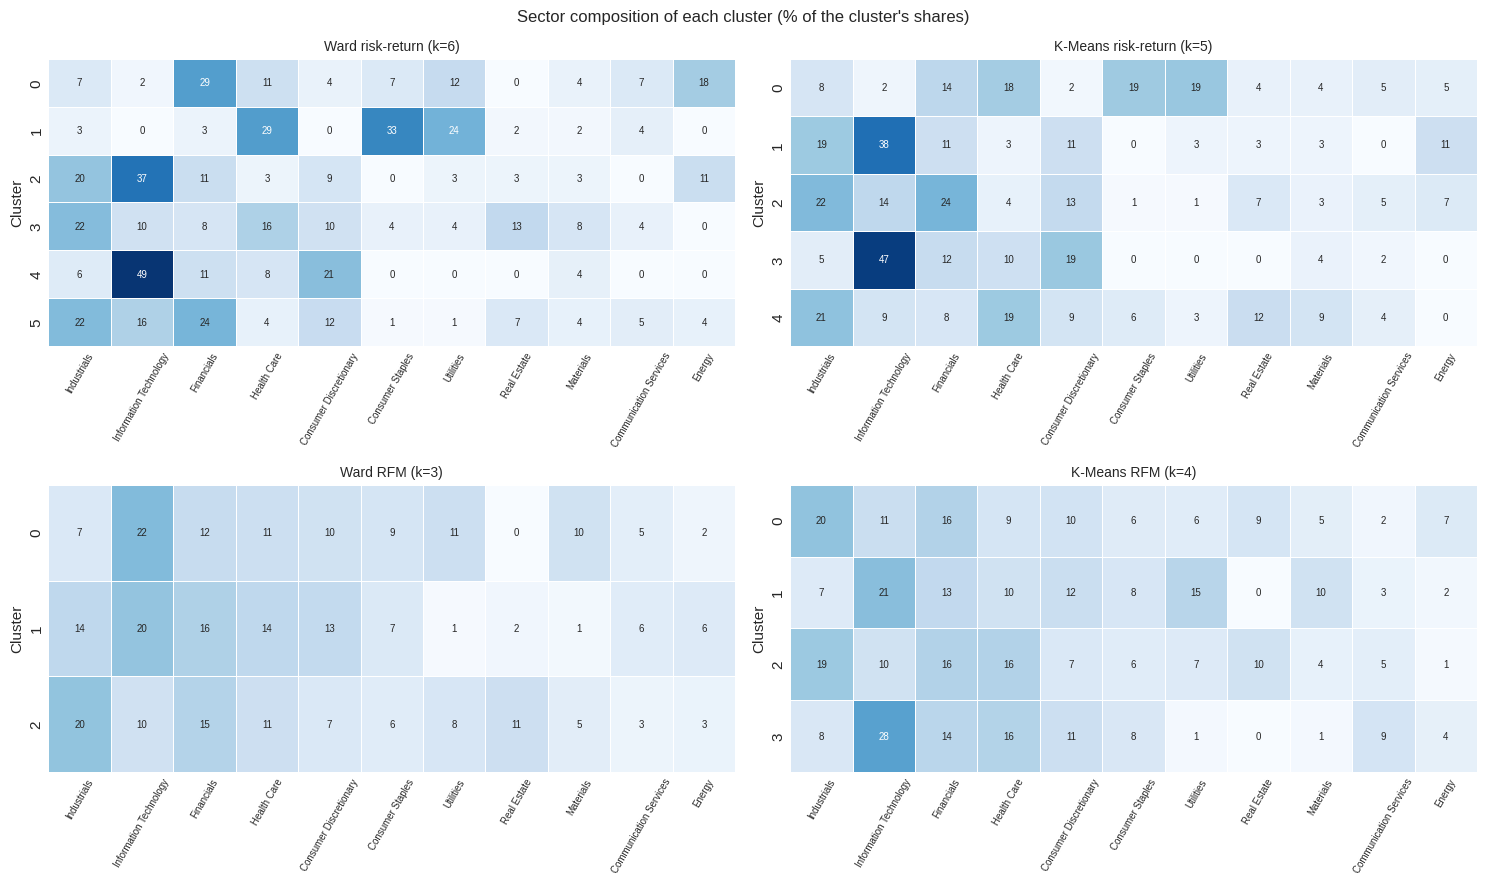

In [101]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

solutions = {
    f'Ward risk-return (k={best_rr_k_agg})': agg_rr_labels,
    f'K-Means risk-return (k={best_rr_k_km})': km_rr_labels,
    f'Ward RFM (k={best_rfm_k_agg})':          agg_rfm_labels,
    f'K-Means RFM (k={best_rfm_k_km})':        km_rfm_labels,
}

sector_all = df['GICS Sector'].value_counts(normalize=True) * 100      # whole-sample mix

def sector_table(labels):
    """% of each cluster's shares in each sector (rows add to 100)."""
    ct = pd.crosstab(pd.Series(labels, index=df.index, name='Cluster'), df['GICS Sector'], normalize='index') * 100
    return ct.reindex(columns=sector_all.index).round(1)

sector_tables = {name: sector_table(lbl) for name, lbl in solutions.items()}

for name, t in sector_tables.items():
    print(f"\n=== {name}: % of cluster in each sector (whole sample shown last) ===")
    print(pd.concat([t, sector_all.round(1).to_frame('All shares').T]).to_string())

# Chart 11 - heat maps of sector share (4 panels)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (name, t) in zip(axes.flat, sector_tables.items()):
    sns.heatmap(t, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=50,
                linewidths=.4, cbar=False, ax=ax, annot_kws={'size': 7})
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Cluster')
    ax.tick_params(axis='x', labelrotation=60, labelsize=7)
fig.suptitle('Sector composition of each cluster (% of the cluster\'s shares)', fontsize=12)
fig.tight_layout()
fig.savefig('chart11_sector_composition.png', dpi=300)
plt.show()


3.2.1 Do risk-return clusters and RFM clusters describe the same shares? (Chart 12)

Ward: ARI between risk-return and RFM clusters = 0.025
K-Means: ARI between risk-return and RFM clusters = 0.016


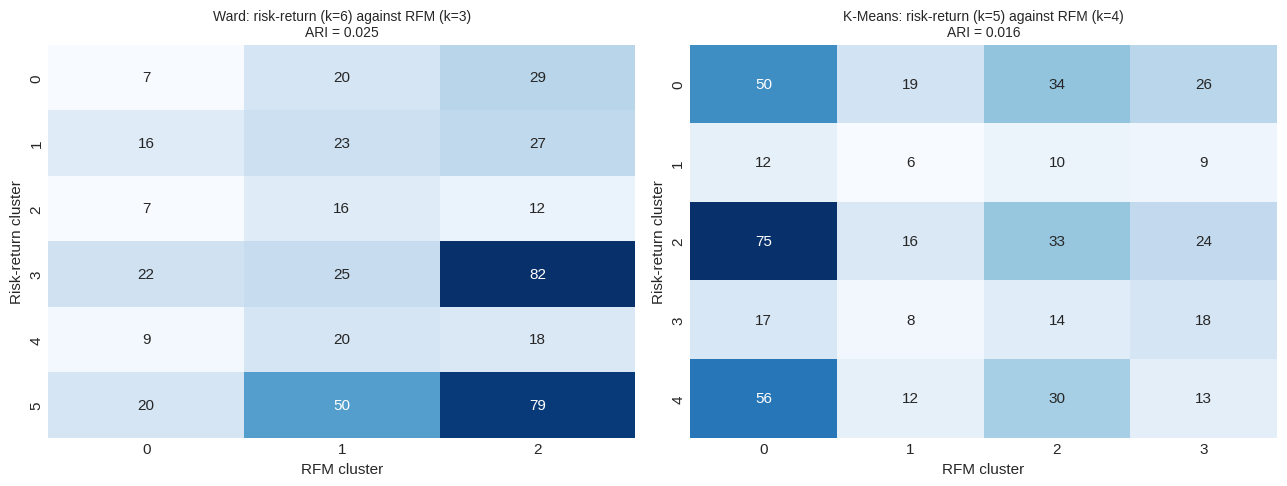

In [102]:
from sklearn.metrics import adjusted_rand_score

pairs = [
    ('Ward',    agg_rr_labels, agg_rfm_labels, best_rr_k_agg, best_rfm_k_agg),
    ('K-Means', km_rr_labels,  km_rfm_labels,  best_rr_k_km,  best_rfm_k_km),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (alg, rr_l, rfm_l, k_rr, k_rfm) in zip(axes, pairs):
    ct = pd.crosstab(pd.Series(rr_l, name='Risk-return cluster'),
                     pd.Series(rfm_l, name='RFM cluster'))
    sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ari = adjusted_rand_score(rr_l, rfm_l)
    ax.set_title(f'{alg}: risk-return (k={k_rr}) against RFM (k={k_rfm})\nARI = {ari:.3f}', fontsize=10)
    print(f'{alg}: ARI between risk-return and RFM clusters = {ari:.3f}')
fig.tight_layout()
fig.savefig('chart12_rr_vs_rfm.png', dpi=300)
plt.show()

In [103]:
def profile_table(labels, view):
    d = df.assign(Cluster=labels); g = d.groupby('Cluster')
    top = pd.crosstab(d['Cluster'], d['GICS Sector'], normalize='index') * 100
    out = pd.DataFrame({
        'Shares': g.size(),
        'Mean weekly return (%)': g['Mean_Weekly_Return'].mean() * 100,
        'Mean beta': g['Weekly_Beta'].mean(),
        'Mean Recency (days)': g['Recency'].mean(),
        'Mean Frequency': g['Frequency'].mean(),
        'Median Monetary ($bn)': g['Monetary'].median() / 1e9,
        'Largest sector': top.idxmax(axis=1),
        'Largest sector (%)': top.max(axis=1)}).round(3)
    out.insert(0, 'Solution', view)
    return out

profiles = pd.concat([profile_table(l, n) for n, l in solutions.items()])
display(profiles)
profiles.to_csv('cluster_profiles_task3.csv')

,Solution,Shares,Mean weekly return (%),Mean beta,Mean Recency (days),Mean Frequency,Median Monetary ($bn),Largest sector,Largest sector (%)
Cluster,,,,,,,,,
0,Ward risk-return (k=6),56,0.418,0.577,18.804,2.857,17.396,Financials,28.571
1,Ward risk-return (k=6),66,0.088,0.439,26.197,2.894,17.701,Consumer Staples,33.333
2,Ward risk-return (k=6),35,0.876,1.367,26.343,3.257,25.227,Information Technology,37.143
3,Ward risk-return (k=6),129,0.075,0.959,17.977,3.078,12.891,Industrials,21.705
4,Ward risk-return (k=6),47,0.196,1.620,23.128,3.170,28.918,Information Technology,48.936
5,Ward risk-return (k=6),149,0.391,1.051,18.168,2.866,17.699,Financials,23.490
0,K-Means risk-return (k=5),129,0.242,0.523,22.062,2.907,15.353,Utilities,19.380
1,K-Means risk-return (k=5),37,0.862,1.364,26.270,3.351,24.647,Information Technology,37.838
2,K-Means risk-return (k=5),148,0.397,1.022,17.588,2.845,17.815,Financials,23.649
